## NAMA : A. ACHMAD RAIHAN. AM
## NIM : H061241007
## KELAS C
## TUGAS 2 KECERDASAN ARTIFISIAL DALAM GEOFISIKA

# (1) PROMPT (ChatGPT)

> **Role:** Bertindaklah sebagai Ahli Geofisika senior yang berspesialisasi dalam Penginderaan Jauh (*Remote Sensing*) dan pemrosesan data radar (InSAR).
> **Context:** Sebuah pemerintah kota pesisir sedang menghadapi masalah banjir rob yang semakin parah setiap tahunnya. Mereka mencurigai penyebab utamanya adalah ekstraksi air tanah berlebih yang memicu penurunan muka tanah (*land subsidence*). Mereka membutuhkan rekomendasi teknis untuk memetakan zona paling kritis guna merencanakan infrastruktur tanggul laut.
> **Task:** Susunlah alur kerja (*workflow*) pengolahan data satelit untuk memetakan dan menghitung laju penurunan muka tanah dalam milimeter/tahun, serta berikan panduan cara menginterpretasikan peta hasil akhirnya kepada pemangku kebijakan yang bukan orang teknis.
> **Input:** Data yang tersedia saat ini adalah kumpulan citra radar satelit Sentinel-1A (format SLC) periode Januari 2021 hingga Desember 2023, serta data topografi DEM SRTM 30m.
> **Constraints:**
> * Gunakan metode *Persistent Scatterer Interferometry* (PS-InSAR) sebagai pendekatan utama.
> * Hindari penurunan rumus atau persamaan matematika yang rumit; fokuslah pada tahapan praktis, konsep geofisis, dan parameter kualitas data (seperti koherensi).
> * Batasi penjelasan maksimal 500 kata.

# Workflow PS-InSAR untuk Pemetaan dan Estimasi Laju Land Subsidence

## 1. Tujuan

Studi ini bertujuan untuk memetakan **penurunan muka tanah (*land subsidence*)** di wilayah kota pesisir menggunakan metode **Persistent Scatterer Interferometry (PS-InSAR)**. Data yang digunakan adalah:

* **Sentinel-1A SLC** periode Januari 2021–Desember 2023
* **DEM SRTM 30 m**
* Data pendukung untuk validasi, apabila tersedia, seperti GNSS atau leveling

Hasil utama yang diharapkan adalah **peta laju penurunan muka tanah dalam mm/tahun** yang dapat digunakan untuk mengidentifikasi zona kritis sebagai dasar perencanaan infrastruktur pengendalian banjir rob.

---

## 2. Workflow Pengolahan PS-InSAR

### Tahap 1 — Persiapan dan Seleksi Data

* Kumpulkan seluruh data **Sentinel-1A SLC** dari Januari 2021 hingga Desember 2023.
* Gunakan data dengan **lintasan/orbit yang sama** dan konfigurasi akuisisi yang konsisten.
* Data **ascending** dan **descending** dapat digunakan untuk memperoleh informasi deformasi dari dua arah pengamatan.
* Periksa tanggal akuisisi dan keberadaan data yang hilang.
* Evaluasi **temporal baseline** dan **spatial baseline** untuk membangun jaringan interferogram yang berkualitas.
* Gunakan **Precise Orbit** untuk meningkatkan ketelitian posisi satelit.

---

### Tahap 2 — Pra-pemrosesan

Proses utama yang dilakukan:

1. Apply Orbit File
2. Menentukan satu citra sebagai master/reference
3. Melakukan coregistration seluruh citra SLC terhadap master
4. Menggunakan DEM SRTM 30 m untuk menghilangkan kontribusi fase akibat topografi

Tujuan tahap ini adalah memastikan seluruh citra memiliki referensi geometrik yang sama sehingga perubahan fase dapat dikaitkan dengan deformasi permukaan.

---

### Tahap 3 — Pembentukan Interferogram

* Bentuk interferogram dari pasangan citra yang memiliki hubungan temporal dan geometrik yang baik.
* Hitung **coherence** untuk mengetahui kestabilan fase.
* Area dengan coherence rendah perlu disaring karena informasi deformasinya kurang dapat dipercaya.

Pada wilayah perkotaan, objek permanen seperti:

* bangunan,
* jalan,
* jembatan,
* tiang,
* struktur beton,

biasanya lebih mudah menghasilkan **Persistent Scatterer (PS)** dibandingkan vegetasi atau permukaan yang berubah-ubah.

---

### Tahap 4 — Identifikasi Persistent Scatterer

Kandidat PS dipilih berdasarkan **kestabilan amplitudo dan fase** sepanjang periode pengamatan.

Gunakan parameter kualitas seperti:

* Coherence
* Stabilitas amplitudo
* Kualitas fase
* Kepadatan titik PS

Sebagai nilai awal, **coherence > 0,7** dapat digunakan sebagai ambang penyaringan, kemudian disesuaikan dengan karakteristik wilayah penelitian.

---

### Tahap 5 — Koreksi dan Pemrosesan Fase

Pada tahap ini dilakukan:

1. Phase unwrapping
2. Estimasi deformasi
3. Koreksi residual topografi
4. Estimasi dan penghilangan Atmospheric Phase Screen (APS)
5. Penyaringan noise

Komponen fase yang tidak berkaitan dengan deformasi harus dikurangi agar perubahan fase yang tersisa terutama merepresentasikan pergerakan permukaan tanah.

---

### Tahap 6 — Estimasi Laju Deformasi

Dari deret waktu fase yang telah dikoreksi, hitung **laju deformasi LOS (*Line-of-Sight*)**.

Hasil dapat ditampilkan sebagai:

```text
-5 mm/tahun
-15 mm/tahun
-30 mm/tahun
```

Nilai negatif umumnya menunjukkan permukaan bergerak **menjauh dari satelit**, yang dalam kondisi tertentu dapat berkaitan dengan penurunan muka tanah.

> **Catatan penting:** Sentinel-1 mengukur perpindahan pada arah **LOS**, sehingga nilai LOS tidak selalu sama dengan penurunan vertikal.

Untuk memperoleh **subsidence vertikal**, sebaiknya gunakan kombinasi data **ascending dan descending** atau pendekatan tambahan yang mempertimbangkan komponen horizontal.

---

### Tahap 7 — Validasi Hasil

Hasil PS-InSAR perlu dibandingkan dengan data pengamatan independen apabila tersedia, seperti:

* GNSS/GPS geodetik
* Leveling
* Tide gauge
* Data pengukuran muka tanah
* Data penurunan tanah dari survei lapangan

Validasi penting untuk memastikan bahwa pola deformasi yang diperoleh bukan hanya berasal dari kesalahan atmosfer, noise, atau artefak pemrosesan.

---

# 3. Interpretasi Peta Land Subsidence

Untuk komunikasi kepada pemangku kebijakan nonteknis, hasil dapat disederhanakan menjadi beberapa kelas:

| Laju Penurunan   | Interpretasi     |
| ---------------- | ---------------- |
| `< 5 mm/tahun`   | Relatif stabil   |
| `5–15 mm/tahun`  | Penurunan sedang |
| `15–30 mm/tahun` | Penurunan tinggi |
| `> 30 mm/tahun`  | Zona kritis      |

Semakin besar laju penurunan, semakin cepat elevasi daratan berkurang relatif terhadap permukaan laut. Kondisi ini dapat meningkatkan kerentanan terhadap **banjir rob** dan memperbesar risiko terhadap infrastruktur pesisir.

---

# 4. Penentuan Zona Prioritas

Dalam perencanaan tanggul laut, jangan hanya melihat nilai subsidence terbesar.

Zona prioritas sebaiknya ditentukan berdasarkan kombinasi:

**Laju subsidence tinggi + coherence tinggi + kepadatan PS tinggi + kedekatan dengan pantai + keberadaan infrastruktur penting.**

Dengan demikian, peta PS-InSAR tidak hanya menunjukkan **di mana tanah turun**, tetapi juga membantu pemerintah menentukan **wilayah mana yang perlu menjadi prioritas mitigasi**.

---
### OUTPUT

1. **Peta laju land subsidence (mm/tahun)**
2. **Peta coherence**
3. **Peta distribusi Persistent Scatterer**
4. **Peta deformasi kumulatif 2021–2023**
5. **Peta zona prioritas mitigasi banjir rob**
6. **Grafik deret waktu penurunan pada titik-titik PS kritis**

Produk tersebut dapat digunakan sebagai dasar teknis untuk **perencanaan tanggul laut, pengendalian ekstraksi air tanah, pemantauan infrastruktur, dan mitigasi risiko banjir rob**.


    longitude  latitude  velocity_mm_year
0  119.824908 -4.310368         -8.578392
1  119.940143 -4.342781        -20.682755
2  119.896399 -4.388094         -6.958417
3  119.869732 -4.287241         -5.115314
4  119.781204 -4.313054         -5.521676
File CSV simulasi berhasil dibuat.
    longitude  latitude  velocity_mm_year
0  119.824908 -4.310368         -8.578392
1  119.940143 -4.342781        -20.682755
2  119.896399 -4.388094         -6.958417
3  119.869732 -4.287241         -5.115314
4  119.781204 -4.313054         -5.521676
Jumlah titik PS: 500
Laju minimum: -33.17004302554952 mm/tahun
Laju maksimum: 10.637674701234548 mm/tahun
Laju rata-rata: -9.065225440216926 mm/tahun


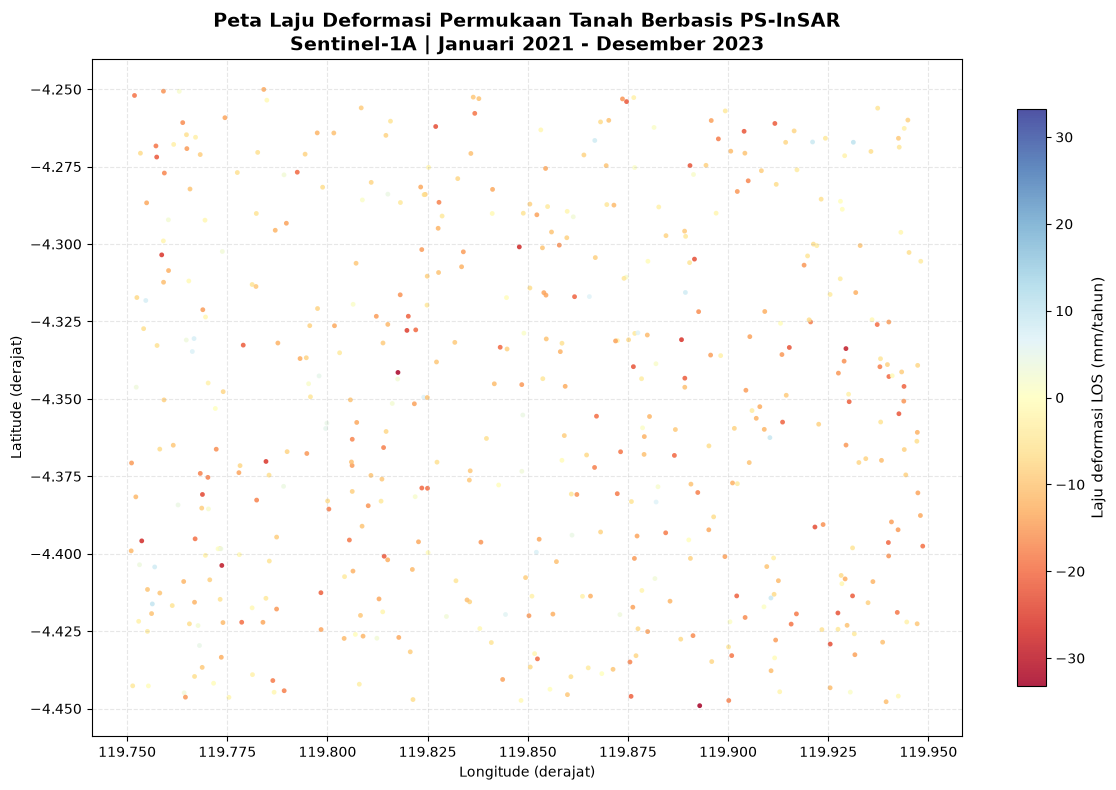

In [3]:

import pandas as pd
import numpy as np

# Membuat data simulasi agar peta bisa diuji
np.random.seed(42)

jumlah_titik = 500

# Membuat koordinat contoh wilayah penelitian
longitude = np.random.uniform(119.75, 119.95, jumlah_titik)
latitude = np.random.uniform(-4.45, -4.25, jumlah_titik)

# Membuat nilai deformasi simulasi dalam mm/tahun
# Nilai negatif dan positif hanya untuk demonstrasi
velocity = np.random.normal(-10, 8, jumlah_titik)

# Menyusun data ke dalam tabel
data = pd.DataFrame({
    "longitude": longitude,
    "latitude": latitude,
    "velocity_mm_year": velocity
})

# Menyimpan data simulasi sebagai CSV
data.to_csv("hasil_psinsar.csv", index=False)

# Memeriksa hasil
print(data.head())
print("File CSV simulasi berhasil dibuat.")


# ============================================================
# PEMETAAN LAJU LAND SUBSIDENCE MENGGUNAKAN HASIL PS-InSAR
# Output: Peta laju deformasi LOS dalam mm/tahun
# Periode pengamatan: Januari 2021 - Desember 2023
# ============================================================

# Mengimpor pandas untuk membaca dan mengolah tabel CSV
import pandas as pd

# Mengimpor matplotlib untuk membuat peta dan legenda warna
import matplotlib.pyplot as plt

# Mengimpor TwoSlopeNorm untuk memusatkan skala warna pada nilai nol
from matplotlib.colors import TwoSlopeNorm

# ------------------------------------------------------------
# 1. MEMBACA DATA HASIL PS-InSAR
# ------------------------------------------------------------

# Membaca file CSV hasil pengolahan PS-InSAR
# File harus memiliki kolom longitude, latitude, velocity_mm_year
data = pd.read_csv("hasil_psinsar.csv")

# Menampilkan lima baris pertama untuk memeriksa data
print(data.head())

# Menghapus baris yang memiliki koordinat atau laju deformasi kosong
data = data.dropna(
    subset=["longitude", "latitude", "velocity_mm_year"]
)

# ------------------------------------------------------------
# 2. MENYIAPKAN NILAI LAJU DEFORMASI
# ------------------------------------------------------------

# Mengambil koordinat bujur setiap titik Persistent Scatterer
longitude = data["longitude"]

# Mengambil koordinat lintang setiap titik Persistent Scatterer
latitude = data["latitude"]

# Mengambil laju deformasi LOS dalam satuan mm/tahun
velocity = data["velocity_mm_year"]

# Menampilkan statistik dasar laju deformasi
print("Jumlah titik PS:", len(data))
print("Laju minimum:", velocity.min(), "mm/tahun")
print("Laju maksimum:", velocity.max(), "mm/tahun")
print("Laju rata-rata:", velocity.mean(), "mm/tahun")

# ------------------------------------------------------------
# 3. MEMBUAT PETA LAJU DEFORMASI
# ------------------------------------------------------------

# Membuat kanvas peta dengan ukuran 12 x 8 inci
fig, ax = plt.subplots(figsize=(12, 8))

# Menentukan rentang warna simetris terhadap nol
# agar deformasi negatif dan positif mudah dibandingkan
limit = max(abs(velocity.min()), abs(velocity.max()))

# Menghindari rentang nol apabila semua nilai sama dengan nol
if limit == 0:
    limit = 1

# Memusatkan skala warna pada nilai nol
norm = TwoSlopeNorm(
    vmin=-limit,
    vcenter=0,
    vmax=limit
)

# Menggambar titik Persistent Scatterer berdasarkan koordinat
# Warna menunjukkan laju deformasi LOS dalam mm/tahun
peta = ax.scatter(
    longitude,
    latitude,
    c=velocity,
    cmap="RdYlBu",
    norm=norm,
    s=12,
    alpha=0.85,
    edgecolors="none"
)

# ------------------------------------------------------------
# 4. MENAMBAHKAN LEGENDA DAN INFORMASI PETA
# ------------------------------------------------------------

# Membuat colorbar untuk menjelaskan arti warna
cbar = plt.colorbar(peta, ax=ax, shrink=0.85)

# Memberikan label satuan laju deformasi
cbar.set_label("Laju deformasi LOS (mm/tahun)", fontsize=11)

# Memberikan judul peta
ax.set_title(
    "Peta Laju Deformasi Permukaan Tanah Berbasis PS-InSAR\n"
    "Sentinel-1A | Januari 2021 - Desember 2023",
    fontsize=14,
    fontweight="bold"
)

# Memberikan label sumbu koordinat
ax.set_xlabel("Longitude (derajat)")
ax.set_ylabel("Latitude (derajat)")

# Menampilkan grid koordinat
ax.grid(True, linestyle="--", alpha=0.3)

# Mengatur tata letak agar elemen peta tidak bertumpuk
plt.tight_layout()

# ------------------------------------------------------------
# 5. MENYIMPAN DAN MENAMPILKAN PETA
# ------------------------------------------------------------

# Menyimpan peta dengan resolusi 300 dpi untuk laporan penelitian
plt.savefig(
    "peta_laju_deformasi_psinsar.png",
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan peta pada layar
plt.show()



# (2) PROMPT (Claude AI)

> **Role:** Bertindaklah sebagai Ahli Geofisika Spesialis Hidrogeofisika yang berpengalaman dalam interpretasi metode geolistrik resistivitas 2D/3D dan eksplorasi air tanah.
> **Context:** Sebuah desa di daerah karst/kering mengalami kekeringan berkepanjangan karena sumur dangkal warga telah mengering. Pemerintah daerah berencana membuat sumur bor dalam (*deep well*). Sebelum pengeboran dilakukan, tim telah melakukan survei geolistrik resistivitas 2D bentangan Wenner-Schlumberger untuk memetakan keberadaan akuifer tertekan (*confined aquifer*) agar pengeboran tidak gagal/salah titik.
> **Task:** Lakukan analisis dan interpretasi terhadap hasil inversi penampang resistivitas geolistrik 2D, identifikasikan lapisan batuan penciri akuifer, serta berikan rekomendasi titik dan kedalaman pengeboran yang paling optimal beserta potensi risikonya.
> **Input:**
> * Konfigurasi pengukuran: Wenner-Schlumberger, 2 lintasan (Panjang lintasan masing-masing 240 meter, spasi elektroda 5 meter).
> * Nilai resistivitas semu/terinversi hasil pengolahan:
> * Lapisan topsoil/tanah permukaan (0 - 3 m): $100 - 300 \ \Omega\text{m}$
> * Lapisan batulempung/sisipan pasiran (3 - 25 m): $5 - 15 \ \Omega\text{m}$
> * Lapisan batu pasir jenuh air / kerakal jenuh (25 - 60 m): $20 - 50 \ \Omega\text{m}$ pada meter ke-100 hingga ke-160 di Lintasan 1.
> * Lapisan batuan dasar / *bedrock* masif (di bawah 60 m): $> 500 \ \Omega\text{m}$
> 
> 
> 
> 
> **Constraints:**
> * Murni gunakan prinsip-prinsip resistivitas geolistrik (seperti Hukum Archie dan kontras resistivitas medium). Jangan memasukkan metode geofisika lain seperti seismik atau seismik refraksi.
> * Sertakan nilai perkiraan kedalaman (dalam meter) secara presisi berdasarkan input data di atas.
> * Jangan gunakan rumus kalkulasi rumit, fokus pada interpretasi kualitatif dan kuantitatif praktis.

# Interpretasi Geolistrik 2D Wenner-Schlumberger untuk Eksplorasi Akuifer Tertekan

**Lokasi:** Desa daerah karst/kering (kekeringan berkepanjangan)
**Tujuan:** Menentukan titik dan kedalaman sumur bor dalam (deep well) pada akuifer tertekan
**Metode:** Geolistrik resistivitas 2D, konfigurasi Wenner-Schlumberger

---

## 1. Ringkasan Eksekutif

| Item | Hasil |
|---|---|
| Akuifer target | Batupasir/kerakal jenuh air, **Lintasan 1, meter ke-100 s.d. ke-160**, kedalaman **±25-60 m** |
| Titik bor utama | **Lintasan 1, meter ke-130** |
| Titik cadangan | Lintasan 1, meter ke-115 dan ke-145 |
| Kedalaman total bor | **±58 m** (maksimum 60 m) |
| Screen | **±29-55 m** |
| Lintasan 2 | Tidak direkomendasikan (tidak ada zona akuifer) |
| Risiko utama | Air payau/asin, pasir lempungan (debit rendah), ketidakpastian kedalaman ±5-8 m |

---

## 2. Parameter Survei dan Kualitas Data

| Parameter | Nilai |
|---|---|
| Konfigurasi | Wenner-Schlumberger |
| Jumlah lintasan | 2 |
| Panjang lintasan | 240 m per lintasan |
| Spasi elektroda | 5 m |
| Jumlah elektroda | 49 per lintasan (240 ÷ 5 + 1) |

**Catatan penting:**

- **Kedalaman investigasi:** Untuk bentangan 240 m, resolusi andal secara praktis hanya sampai sekitar **40-50 m**.
- **Konsekuensi:** Batas bawah akuifer dan puncak bedrock (25-60 m dan di bawah 60 m) berada di zona sensitivitas menurun, sehingga harus dianggap **±5-8 m**, bukan angka pasti.
- **Topografi:** Data elevasi elektroda tidak tersedia. Kedalaman dihitung dari permukaan tanah di titik bor dan perlu dikoreksi bila topografi tidak datar.

---

## 3. Interpretasi Litologi

| Kedalaman (m) | Resistivitas (Ωm) | Interpretasi | Peran hidrogeologi |
|---|---|---|---|
| 0-3 | 100-300 | Tanah/topsoil kering, zona tak jenuh | Zona kering; sumur dangkal warga berada di sini |
| 3-25 | 5-15 | Batulempung dengan sisipan pasiran | **Akuiklud** (lapisan penutup), tebal ±22 m |
| 25-60 | 20-50 | Batupasir/kerakal jenuh air (hanya di meter ke-100 s.d. ke-160, Lintasan 1) | **Akuifer tertekan** (target), tebal ±35 m |
| >60 | >500 | Bedrock masif | Dasar akuifer (akuifug), bukan target bor |

### Dasar penafsiran (kontras resistivitas)

1. **Lempung (5-15 Ωm):** Resistivitas rendah dikendalikan oleh mineral lempung yang menghantarkan arus melalui pertukaran kation. Permeabilitasnya sangat rendah sehingga berfungsi sebagai penyekat.
2. **Pasir/kerakal jenuh (20-50 Ωm):** Lebih resistif daripada lempung karena tekstur kasar mengurangi kontribusi lempung, tetapi masih jauh di bawah batuan kering atau masif.
3. **Susunan akuifer tertekan:** Kombinasi lempung (atas), pasir jenuh (tengah), dan bedrock (bawah) memerangkap air tanah, sehingga muka air berpotensi naik di atas puncak akuifer setelah pemboran.
4. **Bedrock (>500 Ωm):** Porositas dan saturasi sangat rendah, kecuali bila terdapat rongga karst.

---

## 4. Tinjauan Kualitas Air (Hukum Archie, Praktis)

Hukum Archie: resistivitas batuan jenuh ≈ resistivitas air pori × faktor formasi. Untuk pasir berporositas ±25-30%, faktor formasi sekitar **8-10**.

| Skenario | ρ air (Ωm) | ρ formasi yang diharapkan (Ωm) |
|---|---|---|
| Pasir bersih, air tawar | 15-50 | ±100-400 |
| **Teramati di lapangan** | - | **20-50** |

Nilai teramati jauh lebih rendah dari pasir bersih berair tawar. Ada dua kemungkinan penyebab (atau kombinasinya):

1. **Pasir lempungan:** matriks lempung tinggi, porositas efektif dan permeabilitas lebih rendah.
2. **Air payau/asin:** ρ air ≈ 2-6 Ωm (setara DHL ±1.700-5.000 µS/cm), menurunkan resistivitas formasi.

> **Peringatan:** Resistivitas saja **tidak dapat membedakan** kedua kemungkinan ini. Ini adalah risiko terbesar interpretasi dan wajib diverifikasi saat pengeboran.

---

## 5. Rekomendasi Titik Bor

### Titik utama: Lintasan 1, meter ke-130

- Berada di pusat zona konduktif 20-50 Ωm (100-160 m).
- Jarak ±30 m ke tepi anomali di kedua sisi, sebagai margin terhadap pembajian lateral (*pinch-out*).

### Titik cadangan

- Lintasan 1, **meter ke-115**
- Lintasan 1, **meter ke-145**

### Lintasan 2

- Tidak ada zona 20-50 Ωm pada data yang diberikan, sehingga **tidak direkomendasikan** sebagai lokasi bor.
- Bila Lintasan 2 memotong Lintasan 1 di dekat meter ke-130, bandingkan nilai resistivitas di titik silang untuk validasi lateral.

---

## 6. Rekomendasi Kedalaman dan Desain Sumur

| Komponen | Interval / Nilai |
|---|---|
| Kedalaman total bor | **±58 m** (maksimum 60 m) |
| Pipa buta (casing) | **0-27 m** (menembus topsoil dan lempung) |
| Seal/grouting (semen atau bentonit) | **±22-27 m** (dasar lempung) |
| Saringan (screen) | **±29-55 m** (hanya pada interval pasir/kerakal) |
| Pipa penampung (sump) | **±55-58 m** |

**Alasan berhenti di ±58 m:** Puncak bedrock diperkirakan di ±60 m (ketidakpastian ±5-8 m). Menembus bedrock tidak menambah debit dan berisiko mengenai rongga karst atau batuan tanpa air.

### Kontrol saat pengeboran

- Lakukan **bor pilot** dan **electrical logging sumur** untuk menentukan batas lempung/pasir dan puncak bedrock sebenarnya sebelum memasang screen.
- Pasang screen berdasarkan **hasil log**, bukan angka desain semata.
- Bila bedrock lebih dangkal dari 55 m, hentikan pengeboran di puncak bedrock dan sesuaikan panjang screen.

---

## 7. Potensi Risiko dan Mitigasi

| No | Risiko | Penjelasan | Mitigasi |
|---|---|---|---|
| 1 | Air payau/asin | Resistivitas rendah bisa akibat salinitas | Ukur DHL/TDS saat uji pompa awal; bila melebihi standar, gunakan untuk non-konsumsi atau olah air |
| 2 | Pasir lempungan, debit rendah | 20-50 Ωm bisa berarti permeabilitas rendah | Uji pompa 24-72 jam |
| 3 | Ketidakpastian kedalaman | Bentangan 240 m membuat batas ±60 m tidak pasti (±5-8 m) | Bor pilot dan electrical logging |
| 4 | Ekuivalensi inversi | Ketebalan lempung dan pasir bisa bertukar ±3-5 m | Log sumur |
| 5 | Pinch-out lateral | Akuifer hanya teramati selebar ±60 m | Bor tepat di meter ke-130; gunakan titik cadangan bila perlu |
| 6 | Lempung mengembang/runtuh | Lempung 5-15 Ωm dapat merusak dinding lubang | Lumpur bor sesuai dan pasang casing segera |
| 7 | Kontaminasi silang | Seal buruk membocorkan air dangkal ke akuifer tertekan | Grouting yang baik di dasar lempung |
| 8 | Rongga karst | Bedrock >500 Ωm bisa menyembunyikan rongga | Jangan menembus bedrock |

---

### OUTPUT

**1. Model litologi dan hidrogeologi bawah permukaan**
- 0-3 m: topsoil kering (100-300 Ωm)
- 3-25 m: batulempung, sebagai lapisan penutup/akuiklud (5-15 Ωm)
- 25-60 m: batupasir/kerakal jenuh air, sebagai akuifer tertekan (20-50 Ωm)
- di bawah 60 m: bedrock masif, sebagai dasar akuifer (>500 Ωm)

**2. Lokasi akuifer target**
Akuifer hanya terdeteksi di **Lintasan 1, meter ke-100 sampai ke-160**. Lintasan 2 tidak menunjukkan zona akuifer sehingga tidak direkomendasikan untuk pengeboran.

**3. Titik bor dan desain sumur**
- Titik utama: **Lintasan 1, meter ke-130**. Titik cadangan: meter ke-115 dan ke-145.
- Kedalaman total: **±58 m**.
- Casing 0-27 m, seal/grouting di ±22-27 m, screen ±29-55 m, sump ±55-58 m.

**4. Penilaian kualitas air dari prinsip Archie**
Resistivitas akuifer (20-50 Ωm) lebih rendah dari yang diharapkan untuk pasir bersih berair tawar. Penyebabnya bisa pasir lempungan (debit rendah) atau air payau/asin. Resistivitas saja tidak bisa membedakan keduanya, sehingga harus dicek saat pengeboran.

**5. Risiko dan langkah mitigasi**
Risiko utamanya adalah air payau, debit rendah, ketidakpastian kedalaman (±5-8 m), pinch-out lateral, lempung runtuh atau mengembang, kontaminasi silang, dan rongga karst. Mitigasinya:
- bor pilot dan electrical logging sumur,
- pemasangan screen berdasarkan hasil log,
- uji pompa 24-72 jam,
- pengukuran DHL/TDS air.

**Inti hasilnya:** bor satu sumur di Lintasan 1 meter ke-130 sampai kedalaman ±58 m, dengan screen hanya di lapisan pasir/kerakal jenuh air, lalu verifikasi kualitas dan debit air sebelum sumur digunakan warga.

Jika maksud Anda format output tertentu (misalnya laporan Word/PDF, penampang resistivitas ilustratif, atau tabel ringkas untuk pemerintah daerah), beri tahu saya dan saya buatkan.


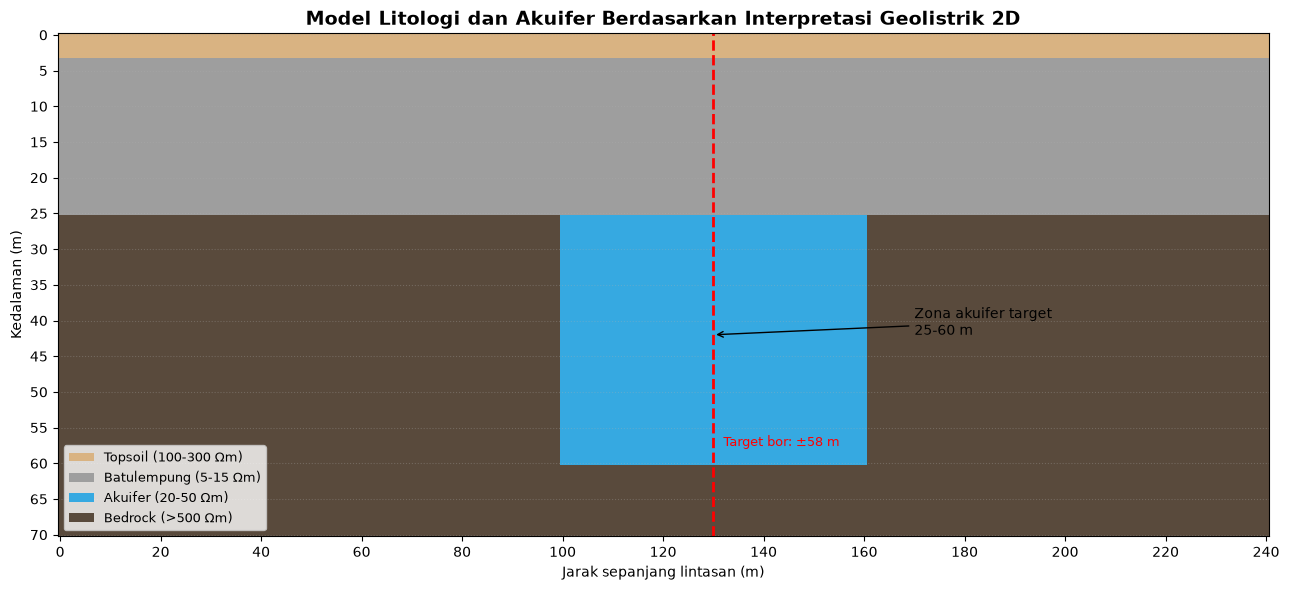

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# =========================================================
# 1. MENENTUKAN DIMENSI LINTASAN GEOLISTRIK
# =========================================================

# Panjang lintasan pengukuran adalah 240 meter
x = np.linspace(0, 240, 241)

# Kedalaman model dari permukaan hingga 70 meter
z = np.linspace(0, 70, 141)

# Membuat grid koordinat horizontal dan vertikal
X, Z = np.meshgrid(x, z)

# =========================================================
# 2. MEMBUAT MODEL RESISTIVITAS ILUSTRATIF
# =========================================================

# Menginisialisasi seluruh model dengan nilai resistivitas
# batuan dasar, yaitu lebih dari 500 ohm meter
resistivitas = np.full_like(X, 600.0)

# Lapisan topsoil: kedalaman 0-3 meter
resistivitas[Z <= 3] = 200.0

# Lapisan batulempung: kedalaman 3-25 meter
lempung = (Z > 3) & (Z <= 25)
resistivitas[lempung] = 10.0

# Zona akuifer ilustratif pada lintasan 1:
# posisi horizontal 100-160 meter
# kedalaman 25-60 meter
akuifer = (
    (X >= 100) & (X <= 160) &
    (Z > 25) & (Z <= 60)
)
resistivitas[akuifer] = 35.0

# =========================================================
# 3. MEMBUAT PENAMPANG LITOLOGI
# =========================================================

# Warna untuk masing-masing satuan litologi
warna = [
    "#D9B382",  # Topsoil
    "#9E9E9E",  # Batulempung
    "#36A9E1",  # Akuifer
    "#594A3C"   # Batuan dasar
]

cmap = ListedColormap(warna)

# Membuat kelas litologi berdasarkan kedalaman dan lokasi
litologi = np.full_like(X, 3, dtype=int)
litologi[Z <= 3] = 0
litologi[lempung] = 1
litologi[akuifer] = 2

# Menggambar penampang 2D
fig, ax = plt.subplots(figsize=(13, 6))

ax.pcolormesh(
    X, Z, litologi,
    cmap=cmap,
    vmin=0,
    vmax=3,
    shading="auto"
)

# Membalik sumbu agar kedalaman bertambah ke bawah
ax.invert_yaxis()

# =========================================================
# 4. MENANDAI TITIK REKOMENDASI PENGEBORAN
# =========================================================

# Titik bor utama berada pada meter ke-130
ax.axvline(
    x=130,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Titik bor utama"
)

# Menandai interval akuifer target
ax.annotate(
    "Zona akuifer target\n25-60 m",
    xy=(130, 42),
    xytext=(170, 42),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10
)

# Menampilkan kedalaman rekomendasi pengeboran
ax.text(
    132, 58,
    "Target bor: ±58 m",
    color="red",
    fontsize=9,
    va="bottom"
)

# =========================================================
# 5. MEMBERIKAN LABEL DAN LEGENDA
# =========================================================

ax.set_title(
    "Model Litologi dan Akuifer Berdasarkan Interpretasi "
    "Geolistrik 2D",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Jarak sepanjang lintasan (m)")
ax.set_ylabel("Kedalaman (m)")

ax.set_xticks(np.arange(0, 241, 20))
ax.set_yticks(np.arange(0, 71, 5))
ax.grid(axis="y", linestyle=":", alpha=0.3)

legenda = [
    Patch(facecolor=warna[0], label="Topsoil (100-300 Ωm)"),
    Patch(facecolor=warna[1], label="Batulempung (5-15 Ωm)"),
    Patch(facecolor=warna[2], label="Akuifer (20-50 Ωm)"),
    Patch(facecolor=warna[3], label="Bedrock (>500 Ωm)")
]

ax.legend(
    handles=legenda,
    loc="lower left",
    fontsize=9
)

plt.tight_layout()

# Menyimpan gambar untuk laporan
plt.savefig(
    "model_litologi_akuifer_2D.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# (3) PROMPT (Gemini AI)

> **Role:** Bertindaklah sebagai Ahli Geofisika Komputasi dan Inversi (*Geophysical Inversion Specialist*) yang berpengalaman dalam pemodelan data elektromagnetik (Magnetotellurik/MT) untuk eksplorasi panas bumi (*geothermal*).
> **Context:** Sebuah tim eksplorasi geothermal sedang mengevaluasi hasil inversi data Magnetotellurik (MT) 1D/2D di area prospek gunung api untuk menentukan kedalaman *clay cap* (lapisan penudung) dan batas *reservoir*. Namun, tim menghadapi kendala di mana model inversi yang dihasilkan sangat sensitif terhadap parameter regulerisasi (*damping parameter*) dan mengalami masalah ekivalensi/ketidaktunggalan solusi (*non-uniqueness*), sehingga menimbulkan ketidakpastian tinggi saat menentukan titik target pemboran eksplorasi.
> **Task:** Lakukan evaluasi terhadap respons kurva MT dan model inversi yang dihasilkan, jelaskan implikasi fisis dari kontras resistivitas terhadap sistem geothermal, serta berikan rekomendasi parameterisasi inversi yang tepat untuk mereduksi *non-uniqueness*.
> **Input:**
> * **Data Respons Kurva MT (Resistivitas Semu & Fase):**
> * *Periode pendek ($10^{-3} - 10^{-1}\text{ s}$):* Resistivitas tinggi ($100 - 300\ \Omega\text{m}$), fase $\approx 45^\circ$.
> * *Periode menengah ($10^{-1} - 10^{1}\text{ s}$):* Resistivitas turun drastis ke amat rendah ($2 - 8\ \Omega\text{m}$), fase melonjak ke $>60^\circ$.
> * *Periode panjang ($10^{1} - 10^{3}\text{ s}$):* Resistivitas naik kembali secara moderat ($30 - 100\ \Omega\text{m}$), fase turun ke $<45^\circ$.
> 
> 
> * **Parameter Inversi Saat Ini:** Menggunakan alogaritma Occam (Smooth Inversion) 1D/2D dengan *misfit RMS* target $3\%$.
> 
> 
> **Constraints:**
> * Jelaskan konsep matematis/statistika inversi (seperti fungsi objektif, regulerisasi Tikhonov/misfit trade-off) secara intuitif dan konseptual tanpa menurunkan persamaan kalkulus rumit.
> * Pembahasan harus mencakup analisis masalah ekivalensi (*S-equivalence* dan *T-equivalence*) yang umum terjadi pada lapisan konduktif (*clay cap*).
> * Fokus pada solusi praktis yang dapat diterapkan di perangkat lunak inversi MT (seperti WinGLink, ModEM, atau SimPEG).

# Evaluasi Inversi Data Magnetotellurik (MT) untuk Prospek Geothermal

---

## 1. Evaluasi Respons Kurva MT dan Implikasi Fisis Sistem Geothermal

Respon kurva Magnetotellurik (MT) yang teramati mencerminkan profil alterasi hidrothermal khas pada sistem geothermal vulkanik (*volcanic geothermal system*):

| Rentang Periode | Karakteristik Kurva ($\rho_a$ & Fase) | Diagnosa Geofisika & Sensitivitas | Implikasi Fisis & Mineralogi Subsurface |
| --- | --- | --- | --- |
| **Pendek** ($10^{-3} - 10^{-1}\text{ s}$) | $\rho_a$ tinggi ($100 - 300\ \Omega\text{m}$)<br>

<br>Fase $\approx 45^\circ$ | Penetrasi dangkal; penetrasi EM terbatas pada zona teratas. Fase $45^\circ$ mengindikasikan medium homogen/transisi datar. | **Overburden / Un-altered Volcanics**: Batuan penutup yang terdiri dari produk vulkanik segar (aliran lava, tuf segar, atau breksi) yang belum teralterasi berat atau berada di atas *water table*. |
| **Menengah** ($10^{-1} - 10^{1}\text{ s}$) | $\rho_a$ turun drastis ($2 - 8\ \Omega\text{m}$)<br>

<br>Fase melonjak $> 60^\circ$ | Kontras konduktivitas tinggi di kedalaman menengah. Fase $> 45^\circ$ menandakan transisi dari resistif ke konduktif terhadap kedalaman. | **Clay Cap (Lapisan Penudung)**: Zona alterasi argilik temperatur rendah ($<200^\circ\text{C}$). Konduktivitas sangat tinggi dipicu oleh tingginya *Cation Exchange Capacity* (CEC) dari mineral lempung smektit dan interstratifikasi smektit-illit. |
| **Panjang** ($10^{1} - 10^{3}\text{ s}$) | $\rho_a$ naik moderat ($30 - 100\ \Omega\text{m}$)<br>

<br>Fase turun $< 45^\circ$ | Penetrasi EM menyentuh kedalaman dalam. Fase $< 45^\circ$ menandakan transisi dari konduktif ke resistif terhadap kedalaman. | **Geothermal Reservoir**: Zona alterasi propilitik temperatur tinggi ($>220^\circ\text{C}$). Smektit bertransformasi menjadi ilit dan klorit dengan CEC jauh lebih rendah. Konduktivitas didominasi oleh konduksi fluida di pori/rekahan. |

---

## 2. Konsep Matematis Inversi, Regulerisasi, dan Misfit Trade-Off

Inversi MT berupaya memprediksi distribusi resistivitas bawah permukaan ($m$) dari data observasi lapangan ($d_{obs}$). Karena jumlah data terbatas dan mengandung noise, masalah inversi bersifat *ill-posed* dan *under-determined*.

Fungsi objektif yang diminimalkan dirumuskan sebagai:

$$\Phi(m) = \Phi_d(m) + \lambda \Phi_m(m)$$

* **Data Misfit ($\Phi_d$)**: Mengukur seberapa dekat respon kalkulasi model $F(m)$ dengan data observasi $d_{obs}$.
* **Model Regularization ($\Phi_m$)**: Hambatan matematis yang membatasi struktur model. Pada regulerisasi Tikhonov, parameter ini mengukur *smoothness* (kehalusan) model ($L_2$-norm dari turunan spasial model) untuk mencegah munculnya anomali ekstrim/spurius akibat memfiting noise.
* **Damping Parameter / Trade-Off ($\lambda$)**: Pengali Lagrange yang mengatur keseimbangan antara kecocokan data (*misfit*) dan kehalusan model (*smoothness*).

### Penyebab Sensitivitas pada Inversi Occam

Algoritma Occam (*Smooth Inversion*) bekerja mencari model paling halus (*smoothest model*) yang masih memenuhi target misfit RMS tertentu.

Ketika target RMS dipaksa terlalu kecil (misalnya $3\%$), sementara data mengandung noise instrumental, efek topografi 3D, atau *static shift*, algoritma dipaksa menurunkan nilai $\lambda$ secara agresif. Akibatnya, kontrol regulerisasi melemah, dan model menjadi **sangat sensitif terhadap variasi kecil pada data**. Hal ini menyebabkan pencarian model terjebak pada *local minima* dan menghasilkan ketidakpastian tinggi pada batas kedalaman.

---

## 3. Analisis Masalah Ekivalensi pada Lapisan Clay Cap

Problem ketidaktunggalan solusi (*non-uniqueness*) saat mengidentifikasi *clay cap* disebabkan oleh fenomena ekivalensi elektromagnetik:

### A. $S$-Equivalence (Konduktansi Terintegrasi)

Pada lapisan konduktif dan tipis seperti *clay cap*, gelombang EM terutama sensitif terhadap **Konduktansi Longitudinal ($S$)**, bukan terhadap ketebalan ($h$) atau resistivitas ($\rho$) secara terpisah:

$$S = \sigma \cdot h = \frac{h}{\rho}$$

* **Implikasi Fisis**: Model *clay cap* dengan ketebalan $h = 200\text{ m}$ dan resistivitas $\rho = 2\ \Omega\text{m}$ menghasilkan $S = 100\text{ S}$. Respons kurva MT yang dihasilkan akan identik dengan model $h = 500\text{ m}$ dan $\rho = 5\ \Omega\text{m}$ (nilai $S = 100\text{ S}$ sama).
* **Dampak Inversi Occam**: Karena inversi Occam mengagungkan kehalusan ($L_2$ *smoothness*), algoritma cenderung **mempertebal $h$ dan menaikkan $\rho$** agar gradien transisi menjadi mulus. Akibatnya, batas atas (*top*) dan batas bawah (*bottom*) *clay cap* mengalami pembiasan/pelebaran (*smearing*), menyebabkan estimasi kedalaman reservoir hidrothermal menjadi tidak tegas.

### B. $T$-Equivalence (Resistansi Transversal)

Terjadi pada lapisan resistif (seperti lapisan *overburden* di atas *clay cap*), di mana MT lebih sensitif terhadap produk perkalian resistivitas dan ketebalan:

$$T = \rho \cdot h$$

Jika $T$ bernilai konstan, variasi $\rho$ dan $h$ pada *overburden* memberikan kurva respon yang relatif sama, yang secara tidak langsung menggeser estimasi kedalaman dimulainya *top of clay cap*.

---

## 4. Rekomendasi Parameterisasi Praktis pada Software Inversi

Untuk mereduksi *non-uniqueness*, mencegah *smearing* pada *clay cap*, dan memberikan batas target pemboran yang tegas, berikut langkah praktis yang dapat diterapkan pada perangkat lunak MT (WinGLink, ModEM, atau SimPEG):

### 1. Penerapan Sharp / Blocky Inversion ($L_1$-norm)

* **SimPEG**: Gunakan regulerisasi *Iteratively Reweighted Least Squares* (IRLS) atau *sparse norm* ($L_1$ atau $L_0$-norm) pada gradien model ($\nabla m$). Pendekatan ini memfasilitasi batas kontras resistivitas yang tajam (*sharp boundaries*) alih-alih transisi mulus $L_2$, sehingga *top* dan *bottom clay cap* terdefinisi dengan jelas.
* **WinGLink / ModEM**: Ubah pembobotan kelurusan spasial. Penggunaan *Blocky Inversion* 1D terlebih dahulu sangat berguna untuk mengunci batas *S-equivalence* sebelum dibawa ke tahap 2D/3D.

### 2. Penyesuaian Error Floor dan L-Curve Analysis

* **Naikkan Error Floor**: Naikkan *Data Error Floor* ke nilai yang lebih realistis untuk menghindari memfiting noise. Atur *Error Floor* sebesar **$5\% - 10\%$ pada resistivitas semu** dan **$1.5^\circ - 3^\circ$ ($5\%$) pada fase** (atau komponen tensor impedansi $Z_{xy}, Z_{yx}$).
* **Analisis L-Curve**: Plot misfit data ($\log \Phi_d$) terhadap kehalusan model ($\log \Phi_m$) untuk berbagai nilai $\lambda$. Pilih nilai $\lambda$ tepat di sudut tekukan (*knee point*).

```
          Log Misfit (Φd)
             |
  Overfitting| \ 
  (Noise Fit)|  \  <-- Pilih Damping Parameter (λ)
             |   \     pada Sudut Tekukan Ini (Knee Point)
             |    +---------------------
             |    |  Oversmoothed Model
             +-------------------------- Log Model Roughness (Φm)

```

### 3. Pembobotan Asimetris Matriks Kovariansi Spasial (Smoothing Scales)

* **ModEM**: Pada matriks kovariansi model ($C_m$), atur skala panjang pemulusan vertikal ($Z$) lebih kecil daripada pemulusan horizontal ($X, Y$).
* Tetapkan rasio $L_z / L_h \approx 0.2 - 0.5$.
* Langkah ini memaksa algoritma menjaga kehalusan secara lateral (mengikuti perlapisan gunung api), namun mengizinkan kontras vertikal yang tajam pada transisi *overburden* $\rightarrow$ *clay cap* $\rightarrow$ *reservoir*.

### 4. Integrasi Prior Information & Koreksi Static Shift

* **Inkorporasi Log Sumur / Geology**: Masukkan kedalaman alterasi dari sumur eksisting ke dalam *Prior Model* ($m_{ref}$) atau manfaatkan *weighting cell* untuk melonggarkan/mengunci regulerisasi pada kedalaman tersebut.
* **Koreksi Static Shift (TDEM / CSAMT)**: Efek *static shift* menggeser kurva resistivitas semu secara vertikal akibat heterogenitas dangkal. Lakukan *Joint Inversion* MT-TDEM atau koreksi pergeseran kurva MT menggunakan data TDEM/CSAMT sebelum pemodelan 2D/3D.

### 5. Analisis Dimensionalitas & Efek Topografi

* Lakukan analisis tensor fase (Phase Tensor). Jika nilai skew angle (∣β∣>3 
∘
 ), struktur memiliki sifat 3D yang dominan.

* Memaksakan inversi 1D/2D pada data bertipe 3D di area vulkanik ber-topografi ekstrem akan memunculkan artifact dan memperparah ekivalensi. Gunakan pemodelan 3D (ModEM 3D) dengan menyertakan Digital Elevation Model (DEM) topografi yang presisi.
### OUTPUT

Output dan hasil akhir (*deliverables*) dari penerapan evaluasi dan koreksi pemodelan inversi MT ini meliputi:

### 1. Model Resistivitas Subsurface yang Presisi (Sharp-Boundary Model)

* **Batas Clay Cap & Reservoir yang Tegas:** Terpetakannya batas atas (*top*) dan batas bawah (*bottom*) lapisan *clay cap* secara spesifik tanpa mengalami pembiasan/pelebaran (*smearing*) akibat efek regulerisasi $L_2$ berlebih.
* **Reduksi Artefak Pemodelan:** Tereliminasinya anomali resistivitas buatan (*spurious anomalies*) yang sebelumnya muncul karena memfiting *noise* data saat dipaksa mencapai RMS $3\%$.

### 2. Set Parameter Inversi Teroptimasi (Software-Ready Config)

* **Nilai Regulerisasi/Damping Parameter ($\lambda$) Optimal:** Diperolehnya nilai $\lambda$ yang seimbang berdasarkan sudut tekukan *L-curve*, mencegah kondisi *over-fitting* maupun *over-smoothing*.
* **Bobot Pemulusan Asimetris:** Penerapan rasio *smoothing scale* vertikal terhadap horizontal ($L_z / L_h \approx 0.2 - 0.5$) pada ModEM atau *sparse regularization* ($L_1$-norm) pada SimPEG untuk merepresentasikan perlapisan vulkanik secara terstratifikasi.
* **Error Floor Realistis:** Pengaturan batas kesalahan data yang aman ($5-10\%$ pada resistivitas semu dan $1.5^\circ-3^\circ$ pada fase).

### 3. Resolusi Masalah Ekivalensi dan Static Shift

* **Kuantifikasi Nilai Konduktansi ($S$):** Kepastian nilai konduktansi terintegrasi ($S = h/\rho$) pada *clay cap* sehingga rentang ketebalan dan resistivitas terisolasi dengan ketidakpastian yang jauh lebih rendah.
* **Koreksi Pergeseran Kurva (Static Shift Correction):** Hasil kalibrasi kurva MT dengan data TDEM/CSAMT atau log sumur eksisting, sehingga kedalaman struktur bawah permukaan tidak mengalami pergeseran vertikal (*depth shift*).

### 4. Peta Rekomendasi Titik Pemboran Sumur Eksplorasi (Well Targeting Decision)

* **Estimasi Kedalaman Casing Shoe & Target Reservoir:** Penentuan kedalaman penancapan pipa selubung (*casing shoe*) yang tepat di dasar *clay cap* sebelum menembus zona reservoir temperatur tinggi ($>220^\circ\text{C}$).
* **Penurunan Risiko Kegagalan Pemboran (*Drilling Risk Reduction*):** Tingkat kepercayaan (*confidence level*) yang lebih tinggi bagi tim geologi dan manajemen dalam menetapkan koordinat dan kedalaman akhir sumur eksplorasi geothermal.

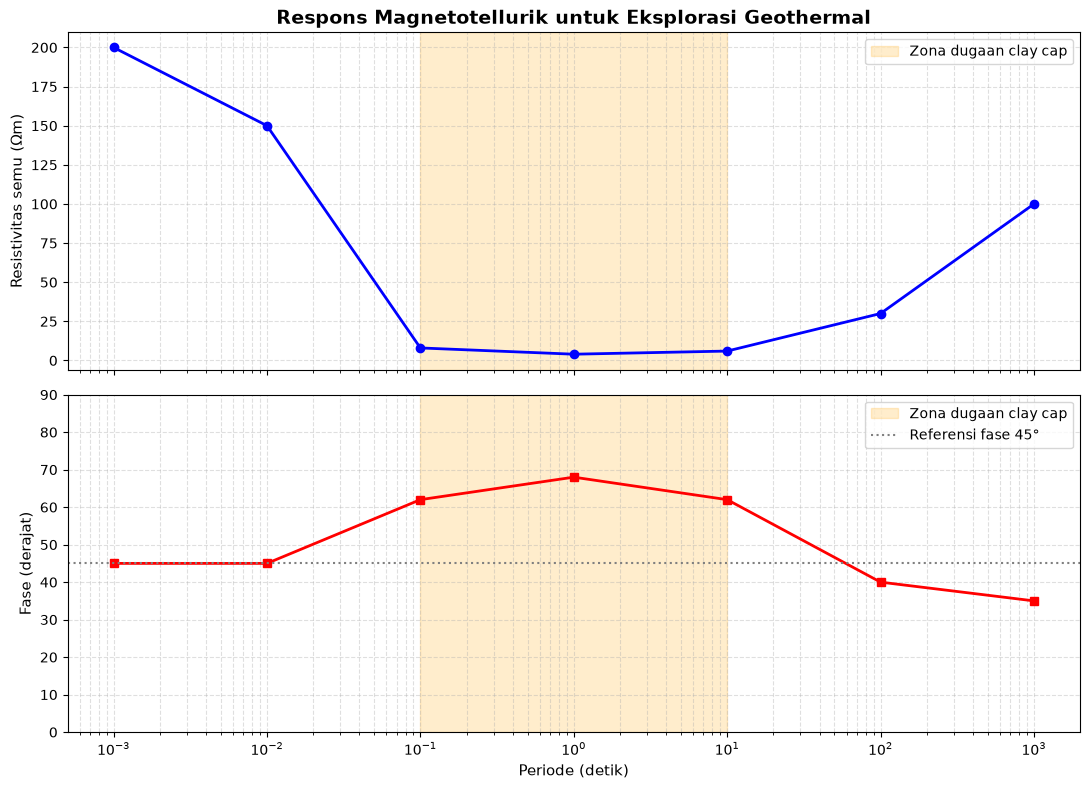

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1. MENYIAPKAN DATA RESPONS MAGNETOTELLURIK (MT)
# =====================================================

# Periode elektromagnetik dalam satuan detik
periode = np.array([0.001, 0.01, 0.1, 1, 10, 100, 1000])

# Resistivitas semu ilustratif (ohm meter)
# Nilai mengikuti kecenderungan rentang pada prompt
resistivitas = np.array([200, 150, 8, 4, 6, 30, 100])

# Fase ilustratif dalam derajat
# Fase periode menengah dibuat >60 derajat
fase = np.array([45, 45, 62, 68, 62, 40, 35])

# =====================================================
# 2. MEMBUAT FIGUR DENGAN DUA GRAFIK
# =====================================================

# Membuat dua panel vertikal dengan sumbu X yang sama
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

# =====================================================
# 3. GRAFIK RESISTIVITAS SEMU
# =====================================================

# Menggambar resistivitas terhadap periode
ax1.semilogx(
    periode,
    resistivitas,
    marker="o",
    color="blue",
    linewidth=2,
    markersize=6
)

# Menandai rentang periode menengah yang mencirikan clay cap
ax1.axvspan(
    0.1, 10,
    alpha=0.2,
    color="orange",
    label="Zona dugaan clay cap"
)

# Memberikan judul dan label sumbu
ax1.set_title(
    "Respons Magnetotellurik untuk Eksplorasi Geothermal",
    fontsize=14,
    fontweight="bold"
)
ax1.set_ylabel("Resistivitas semu (Ωm)", fontsize=11)

# Menampilkan grid dan legenda
ax1.grid(True, which="both", linestyle="--", alpha=0.4)
ax1.legend()

# =====================================================
# 4. GRAFIK FASE
# =====================================================

# Menggambar fase terhadap periode
ax2.semilogx(
    periode,
    fase,
    marker="s",
    color="red",
    linewidth=2,
    markersize=6
)

# Menandai rentang periode menengah
ax2.axvspan(
    0.1, 10,
    alpha=0.2,
    color="orange",
    label="Zona dugaan clay cap"
)

# Menambahkan garis referensi fase 45 derajat
ax2.axhline(
    45,
    color="gray",
    linestyle=":",
    label="Referensi fase 45°"
)

# Memberikan label sumbu
ax2.set_xlabel("Periode (detik)", fontsize=11)
ax2.set_ylabel("Fase (derajat)", fontsize=11)

# Mengatur batas sumbu fase
ax2.set_ylim(0, 90)

# Menampilkan grid dan legenda
ax2.grid(True, which="both", linestyle="--", alpha=0.4)
ax2.legend()

# =====================================================
# 5. MENYIMPAN DAN MENAMPILKAN GRAFIK
# =====================================================

# Mengatur jarak antargrafik
plt.tight_layout()

# Menyimpan gambar dengan resolusi tinggi
plt.savefig(
    "grafik_respons_MT_geothermal.png",
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan hasil
plt.show()


# (4) PROMPT (ChatGPT)


> **Role:** Bertindaklah sebagai Ahli Geodesi dan Penginderaan Jauh Senior yang berspesialisasi dalam analisis deformasi permukaan bumi menggunakan teknik *Persistent Scatterer Interferometry* (PS-InSAR) dan mitigasi bencana geologi.
> **Context:** Badan Perencanaan Pembangunan Daerah (Bappeda) di kota pesisir metropolitan membutuhkan analisis komprehensif mengenai tingkat penurunan muka tanah (*land subsidence*). Fenomena ini diduga dipicu oleh kombinasi konsolidasi alami tanah aluvium muda, beban bangunan (*building load*), dan pemompaan air tanah secara masif. Hasil analisis spasial dan temporal ini akan digunakan sebagai dasar revisi Rencana Detail Tata Ruang (RDTR) dan penetapan zona larangan ekstraksi air tanah.
> **Task:** Lakukan analisis komprehensif terhadap data spasial dan temporal hasil pengolahan PS-InSAR, identifikasikan kluster wilayah kritis, korelasikan pola deformasi dengan faktor geologi/penggunaan lahan, serta susun analisis tren waktu deformasi (linier vs akselerasi) beserta rekomendasi mitigasinya.
> **Input:**
> * **Dataset Citra:** Sentinel-1A/B IW SLC (deret waktu 2018–2024, 72 *scenes*, arah orbit *Descending*).
> * **Dataset Referensi:** DEMNAS (resolusi 8.1 meter) untuk koreksi fase topografi.
> * **Hasil Ekstraksi PS-InSAR (Vertical Displacement Rate & Time-Series):**
> * *Zona Utara (Pesisir & Kawasan Industri):* Kepadatan titik PS tinggi ($>150\text{ PS/km}^2$). Laju rata-rata vertikal: $-70\text{ mm/tahun}$ hingga $-120\text{ mm/tahun}$. Grafik temporal menunjukkan penurunan non-linier yang mengalami akselerasi saat musim kemarau (Juli–Oktober).
> * *Zona Tengah (Pusat Komersial & Pemukiman Padat):* Laju rata-rata vertikal: $-20\text{ mm/tahun}$ hingga $-45\text{ mm/tahun}$. Grafik temporal menunjukkan pola penurunan linier yang konstan.
> * *Zona Selatan (Batuan Sedimen/Perbukitan):* Laju rata-rata vertikal: $0\text{ mm/tahun}$ hingga $-5\text{ mm/tahun}$ (relatif stabil).
> 
> 
> * **Data Pendukung:** Peta Geologi Lembar Lokal (Utara: Aluvium dataran pantai; Selatan: Batuan gunung api tua/padas) dan data titik stasiun GNSS kontinual (satu titik kontrol di Zona Utara mengonfirmasi laju $-85\text{ mm/tahun}$).
> 
> 
> **Constraints:**
> * Fokus analisis wajib terbagi dua: **Spasial** (sebaran horisontal/kluster risiko) dan **Temporal** (perilaku grafik waktu/musim).
> * Gunakan terminologi teknis PS-InSAR yang tepat (seperti *line-of-sight* (LOS) *to vertical conversion*, *coherence threshold* $\ge 0.7$, *reference point*, *atmospheric phase screen* (APS), dan *phase unwrapping error*).
> * Hindari penurunan formula matematika interferometri yang panjang; fokus pada analisis fisik geodesi, interpretasi grafik/peta, dan implikasi keruangannya.
> * Batasi jawaban maksimal 600 kata dengan penyampaian yang lugas, terstruktur, dan berbasis data input.

# Analisis PS-InSAR *Land Subsidence* 2018–2024

Berdasarkan **72 scene Sentinel-1 IW SLC orbit descending**, DEMNAS 8,1 m, hasil PS-InSAR, data geologi, dan satu stasiun GNSS kontinu, pola deformasi menunjukkan **subsidence paling kritis berada di Zona Utara**, sedangkan Zona Selatan relatif stabil. Interpretasi berikut dipisahkan menjadi aspek **spasial** dan **temporal**.

## 1. Analisis Spasial

### Zona Utara – Pesisir & Kawasan Industri

**Zona Utara** merupakan **kluster deformasi paling signifikan**, dengan kepadatan titik PS **>150 PS/km²** dan laju penurunan vertikal sekitar **−70 hingga −120 mm/tahun**. Konsentrasi titik PS yang tinggi menunjukkan bahwa deformasi tersebar luas dan tidak hanya terjadi secara lokal pada satu bangunan.

Secara geologi, kondisi tersebut konsisten dengan keberadaan **aluvium dataran pantai muda** yang umumnya memiliki kompresibilitas tinggi. Selain itu, **beban bangunan (*building load*) dan infrastruktur industri** dapat meningkatkan tegangan efektif pada lapisan tanah sehingga mempercepat proses konsolidasi.

Besarnya laju subsidence juga konsisten dengan kemungkinan adanya **pemompaan air tanah** secara intensif, khususnya pada kawasan industri dan perkotaan. Namun, hubungan sebab-akibat tidak dapat ditentukan hanya berdasarkan PS-InSAR. Untuk mengonfirmasi kontribusi pemompaan air tanah, diperlukan data **muka air tanah, volume ekstraksi, dan recharge**.

Stasiun **GNSS kontinu** di Zona Utara mencatat laju penurunan sekitar **−85 mm/tahun**, yang berada dalam rentang hasil PS-InSAR **−70 hingga −120 mm/tahun**. Hal ini memberikan validasi independen terhadap hasil deformasi, dengan catatan proses **LOS-to-vertical conversion** dilakukan secara tepat dan deformasi diasumsikan didominasi oleh komponen vertikal.

### Zona Tengah – Pusat Komersial & Permukiman Padat

**Zona Tengah** menunjukkan laju penurunan sekitar **−20 hingga −45 mm/tahun**. Meskipun amplitudonya lebih rendah dibandingkan Zona Utara, wilayah ini tetap menunjukkan deformasi yang signifikan.

Pola deformasi kemungkinan berkaitan dengan kombinasi **konsolidasi tanah perkotaan** dan **beban bangunan** yang berlangsung secara relatif kontinu. Karakteristik deformasi yang lebih seragam menunjukkan bahwa proses penurunan berlangsung secara gradual.

### Zona Selatan – Perbukitan/Batuan Sedimen

**Zona Selatan** menunjukkan laju deformasi sekitar **0 hingga −5 mm/tahun**, sehingga dapat dikategorikan sebagai wilayah yang relatif stabil.

Kondisi tersebut berkaitan dengan keberadaan **batuan sedimen/perbukitan dan batuan gunung api tua yang lebih kompeten** dibandingkan aluvium muda di bagian utara. Kontras deformasi antara Zona Utara dan Zona Selatan memperkuat indikasi bahwa **litologi dan kondisi geologi** merupakan faktor penting dalam distribusi spasial subsidence.

## 2. Analisis Temporal

### Zona Utara

Kurva *time-series* PS-InSAR di Zona Utara menunjukkan **tren penurunan non-linier dengan indikasi akselerasi pada periode Juli–Oktober**.

Pola musiman tersebut dapat berasosiasi dengan perubahan kondisi hidrologi, seperti **meningkatnya kebutuhan air tanah pada musim kemarau dan berkurangnya recharge**. Oleh karena itu, terdapat indikasi bahwa faktor hidrogeologi kemungkinan berkontribusi terhadap percepatan subsidence.

Namun demikian, interpretasi ini perlu dikonfirmasi menggunakan data **time-series muka air tanah, curah hujan, dan volume pemompaan** agar hubungan antara perubahan hidrologi dan deformasi dapat dibuktikan secara kuantitatif.

### Zona Tengah

Zona Tengah menunjukkan pola penurunan yang relatif **linier dan konstan** selama periode pengamatan.

Karakteristik tersebut menunjukkan deformasi yang berlangsung secara gradual dan lebih konsisten dengan mekanisme **konsolidasi jangka panjang dan/atau pengaruh beban perkotaan yang relatif stabil**.

## 3. Pengendalian Kualitas PS-InSAR

Untuk memastikan kluster deformasi yang teridentifikasi merupakan sinyal deformasi sebenarnya dan bukan artefak pengolahan, beberapa aspek kualitas PS-InSAR perlu diperhatikan.

* **Coherence threshold ≥ 0,7** digunakan untuk mempertahankan titik PS dengan kestabilan koherensi yang baik.
* **Reference point** harus ditempatkan pada lokasi yang relatif stabil agar estimasi deformasi tidak mengalami pergeseran referensi.
* **Atmospheric Phase Screen (APS)** perlu dikoreksi untuk mengurangi pengaruh variasi atmosfer terhadap fase interferometrik.
* **Phase unwrapping error** harus diperiksa, khususnya pada area dengan gradien deformasi tinggi.
* Kawasan industri perlu dievaluasi terhadap kemungkinan ***decorrelation*** akibat perubahan struktur, aktivitas konstruksi, atau perubahan permukaan.

## 4. Rekomendasi Mitigasi

Untuk **Zona Utara**, prioritas mitigasi meliputi **pengendalian ekstraksi air tanah**, peningkatan pemantauan muka air tanah, serta penguatan jaringan pemantauan deformasi menggunakan **GNSS kontinu dan PS-InSAR**.

Dalam konteks RDTR, wilayah dengan laju deformasi **>−50 mm/tahun** dapat ditetapkan sebagai **area pengawasan intensif**, sedangkan wilayah dengan laju sekitar **−70 hingga −120 mm/tahun** perlu diprioritaskan sebagai **zona deformasi sangat tinggi** untuk evaluasi pembangunan, infrastruktur kritis, dan aktivitas ekstraksi air tanah.

## Kesimpulan

Secara keseluruhan, analisis PS-InSAR menunjukkan bahwa **subsidence paling kuat terkonsentrasi pada aluvium pesisir Zona Utara**, dengan laju mencapai **−120 mm/tahun**. Pola spasial tersebut berkaitan dengan kondisi geologi aluvium muda dan karakteristik penggunaan lahan berupa kawasan industri serta permukiman padat.

Dari sisi temporal, **Zona Utara menunjukkan deformasi non-linier dan akselerasi pada Juli–Oktober**, sedangkan Zona Tengah memperlihatkan tren yang lebih linier dan Zona Selatan relatif stabil. Kombinasi **konsolidasi alami tanah, *building load*, dan pemompaan air tanah** merupakan faktor yang secara fisik dapat menjelaskan pola tersebut, tetapi kontribusi masing-masing faktor perlu diverifikasi menggunakan data hidrogeologi dan data penggunaan air tanah.

Hasil ini dapat digunakan sebagai dasar teknis untuk **pemetaan zona rawan subsidence, revisi RDTR, pengendalian ekstraksi air tanah, serta penentuan wilayah prioritas monitoring dan mitigasi**.

### OUTPUT

Output analisis PS-InSAR menghasilkan gambaran spasial dan temporal mengenai pola penurunan muka tanah pada wilayah kajian selama periode 2018–2024. Secara spasial, hasil utama berupa peta laju deformasi vertikal yang menunjukkan bahwa Zona Utara, khususnya kawasan pesisir dan industri, merupakan wilayah dengan penurunan paling tinggi, yaitu sekitar −70 hingga −120 mm/tahun, sedangkan Zona Tengah mengalami penurunan −20 hingga −45 mm/tahun dan Zona Selatan relatif stabil dengan laju 0 hingga −5 mm/tahun. Hasil tersebut selanjutnya dapat divisualisasikan dalam peta kluster wilayah kritis serta dioverlay dengan peta geologi dan penggunaan lahan untuk mengidentifikasi keterkaitan antara deformasi dengan kondisi aluvium muda, kawasan industri, permukiman padat, dan beban bangunan.

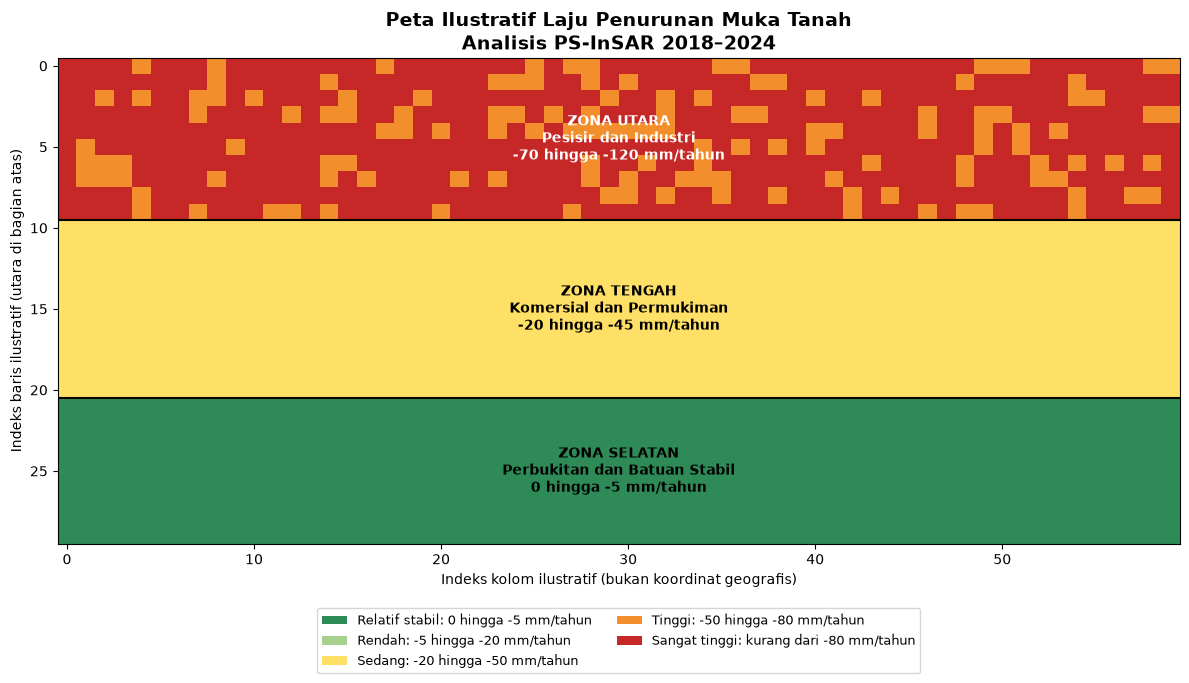

RINGKASAN LAJU PENURUNAN MUKA TANAH
-----------------------------------
Zona Utara   : -94.80 mm/tahun
Zona Tengah  : -32.48 mm/tahun
Zona Selatan : -2.57 mm/tahun

Gambar tersimpan sebagai:
peta_subsidence_PS_InSAR_2018_2024.png


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# =========================================================
# 1. MEMBUAT DATA ILUSTRATIF PS-InSAR
# =========================================================

# Mengatur generator angka acak agar hasil konsisten setiap dijalankan
rng = np.random.default_rng(42)

# Membuat grid ilustratif berukuran 30 baris x 60 kolom
# Grid ini bukan koordinat geografis sebenarnya
baris = 30
kolom = 60

# Membuat array untuk menyimpan laju penurunan (mm/tahun)
subsidence = np.zeros((baris, kolom))

# Zona Utara: pesisir dan kawasan industri
# Laju penurunan berkisar -70 sampai -120 mm/tahun
subsidence[0:10, :] = -70 - 50 * rng.random((10, kolom))

# Zona Tengah: pusat komersial dan permukiman padat
# Laju penurunan berkisar -20 sampai -45 mm/tahun
subsidence[10:21, :] = -20 - 25 * rng.random((11, kolom))

# Zona Selatan: perbukitan dan batuan relatif stabil
# Laju penurunan berkisar 0 sampai -5 mm/tahun
subsidence[21:30, :] = -5 * rng.random((9, kolom))

# =========================================================
# 2. MENGKLASIFIKASIKAN TINGKAT PENURUNAN
# =========================================================

# Kelas 0: relatif stabil, 0 sampai -5 mm/tahun
# Kelas 1: rendah, lebih dari -5 sampai -20 mm/tahun
# Kelas 2: sedang, lebih dari -20 sampai -50 mm/tahun
# Kelas 3: tinggi, lebih dari -50 sampai -80 mm/tahun
# Kelas 4: sangat tinggi, lebih cepat daripada -80 mm/tahun

kelas = np.zeros((baris, kolom), dtype=int)

kelas[(subsidence < -5) & (subsidence >= -20)] = 1
kelas[(subsidence < -20) & (subsidence >= -50)] = 2
kelas[(subsidence < -50) & (subsidence >= -80)] = 3
kelas[subsidence < -80] = 4

# Menentukan warna setiap kelas
warna = [
    "#2E8B57",  # Hijau: relatif stabil
    "#A8D08D",  # Hijau muda: rendah
    "#FFE066",  # Kuning: sedang
    "#F28E2B",  # Oranye: tinggi
    "#C62828"   # Merah: sangat tinggi
]

cmap = ListedColormap(warna)

# =========================================================
# 3. MEMBUAT PETA SPASIAL
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

# Menampilkan klasifikasi penurunan muka tanah
peta = ax.imshow(
    kelas,
    cmap=cmap,
    vmin=0,
    vmax=4,
    origin="upper",
    aspect="auto",
    interpolation="nearest"
)

# Membuat garis batas antara tiga zona
ax.axhline(9.5, color="black", linewidth=1.5)
ax.axhline(20.5, color="black", linewidth=1.5)

# Memberikan keterangan Zona Utara
ax.text(
    29.5, 4.5,
    "ZONA UTARA\nPesisir dan Industri\n-70 hingga -120 mm/tahun",
    ha="center", va="center",
    fontsize=10, fontweight="bold", color="white"
)

# Memberikan keterangan Zona Tengah
ax.text(
    29.5, 15,
    "ZONA TENGAH\nKomersial dan Permukiman\n-20 hingga -45 mm/tahun",
    ha="center", va="center",
    fontsize=10, fontweight="bold", color="black"
)

# Memberikan keterangan Zona Selatan
ax.text(
    29.5, 25,
    "ZONA SELATAN\nPerbukitan dan Batuan Stabil\n0 hingga -5 mm/tahun",
    ha="center", va="center",
    fontsize=10, fontweight="bold", color="black"
)

# Menambahkan judul dan label sumbu
ax.set_title(
    "Peta Ilustratif Laju Penurunan Muka Tanah\n"
    "Analisis PS-InSAR 2018–2024",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Indeks kolom ilustratif (bukan koordinat geografis)")
ax.set_ylabel("Indeks baris ilustratif (utara di bagian atas)")

# =========================================================
# 4. MENAMBAHKAN LEGENDA
# =========================================================

legenda = [
    Patch(facecolor=warna[0],
          label="Relatif stabil: 0 hingga -5 mm/tahun"),
    Patch(facecolor=warna[1],
          label="Rendah: -5 hingga -20 mm/tahun"),
    Patch(facecolor=warna[2],
          label="Sedang: -20 hingga -50 mm/tahun"),
    Patch(facecolor=warna[3],
          label="Tinggi: -50 hingga -80 mm/tahun"),
    Patch(facecolor=warna[4],
          label="Sangat tinggi: kurang dari -80 mm/tahun")
]

ax.legend(
    handles=legenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    fontsize=9
)

# Mengatur tata letak agar elemen grafik tidak bertumpuk
plt.tight_layout()

# =========================================================
# 5. MENYIMPAN DAN MENAMPILKAN HASIL
# =========================================================

# Menyimpan gambar dalam resolusi tinggi
plt.savefig(
    "peta_subsidence_PS_InSAR_2018_2024.png",
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan peta pada layar
plt.show()

# Menampilkan ringkasan nilai rata-rata setiap zona
print("RINGKASAN LAJU PENURUNAN MUKA TANAH")
print("-----------------------------------")
print(f"Zona Utara   : {subsidence[0:10, :].mean():.2f} mm/tahun")
print(f"Zona Tengah  : {subsidence[10:21, :].mean():.2f} mm/tahun")
print(f"Zona Selatan : {subsidence[21:30, :].mean():.2f} mm/tahun")
print("\nGambar tersimpan sebagai:")
print("peta_subsidence_PS_InSAR_2018_2024.png")


# (5) PROMPT (ChatGPT)

> **Role:** Bertindaklah sebagai *Senior WebGIS Developer* dan *Geospatial System Architect* yang berpengalaman dalam membangun infrastruktur data spasial perkotaan (*Spatial Data Infrastructure*).
> **Context:** Pemerintah Kota Makassar (melalui Dinas Penataan Ruang) memerlukan platform WebGIS interaktif yang dapat diakses publik dan internal pemerintah. Platform ini bertujuan untuk memetakan tata ruang kota, infrastruktur publik, serta pemantauan zona rawan banjir genangan dan rob di wilayah pesisir Makassar. Sistem ini harus efisien, ramah pengguna, dan beroperasi di atas infrastruktur server berbiaya hemat tanpa ketergantungan pada lisensi perangkat lunak *proprietary*.
> **Task:** Susunlah rancangan arsitektur sistem WebGIS, rekomendasi *open-source tech stack*, perancangan basis data spasial (PostGIS), serta peta jalan (*roadmap*) pengembangan aplikasi hingga siap dirilis.
> **Input:**
> * **Data Spasial Tersedia:**
> * Vektor (GeoJSON/SHP): Batas Administrasi Kecamatan & Kelurahan se-Kota Makassar, Jaringan Jalan, Peta ZNT (Zona Nilai Tanah), dan Titik Fasilitas Publik.
> * Raster: Citra Satelit Resoluasi Tinggi Kota Makassar dan Peta Genangan Banjir Rob (TIFF).
> 
> 
> * **Sistem Referensi Spasial:** WGS 84 / UTM Zone 50S (EPSG:32750) dan WGS 84 (EPSG:4326).
> * **Target Pengguna:** Masyarakat umum (akses via ponsel/desktop) dan Operator Dinas (akses via desktop).
> 
> 
> **Constraints:**
> * Wajib menggunakan teknologi 100% *Open-Source* (misalnya: PostgreSQL/PostGIS, GeoServer/pg_tileserv, Leaflet.js/Mapbox GL JS/OpenLayers, dan React/Vue). Jangan gunakan produk ESRI (ArcGIS Server/Online).
> * Waktu muat (*load time*) peta dasar dan layer interaktif di perangkat seluler tidak boleh melebihi 3 detik pada jaringan 4G.
> * Harus menerapkan standar *Open Geospatial Consortium* (OGC) seperti WMS, WFS, dan *Vector Tiles* (MVT) untuk efisiensi transfer data.
> * Hindari penulisan baris kode program secara utuh; fokus pada arsitektur, skema tabel basis data, keputusan teknis, dan alur integrasi data.

Untuk konteks Kota Makassar, saya akan memilih arsitektur **PostGIS sebagai pusat data**, **GeoServer sebagai OGC server**, **pg_tileserv sebagai jalur MVT berkecepatan tinggi**, dan **React + MapLibre GL JS** sebagai frontend utama. Pola ini menjaga sistem tetap open-source, hemat sumber daya server, dan cocok untuk pemisahan akses publik–internal.

Catatan penting: **WMS dan WFS adalah standar OGC**, sedangkan **MVT (Mapbox Vector Tile)** adalah format vector tile yang banyak digunakan; untuk standar OGC yang modern untuk data bertile, OGC menyediakan **OGC API – Tiles**. ([Open Geospatial Consortium][1])

# 1. Arsitektur sistem yang direkomendasikan

## 1.1. Gambaran besar

```text
                         INTERNET / INTRANET
                                │
                     ┌──────────▼──────────┐
                     │   Reverse Proxy     │
                     │    Nginx / HTTPS    │
                     └──────────┬──────────┘
                                │
              ┌─────────────────┴─────────────────┐
              │                                   │
       ┌──────▼───────┐                    ┌──────▼───────┐
       │ WebGIS Publik │                    │ WebGIS Admin  │
       │ React         │                    │ React         │
       │ MapLibre GL JS│                    │ MapLibre GL JS│
       └──────┬───────┘                    └──────┬────────┘
              │                                   │
              └────────────────┬──────────────────┘
                               │
                     ┌─────────▼─────────┐
                     │   API Application │
                     │ FastAPI / REST    │
                     └─────────┬─────────┘
                               │
              ┌────────────────┼─────────────────┐
              │                │                 │
       ┌──────▼─────┐   ┌─────▼──────┐   ┌──────▼──────┐
       │ pg_tileserv│   │  GeoServer  │   │  Keycloak   │
       │ MVT        │   │ WMS / WFS   │   │ Auth / RBAC │
       └──────┬─────┘   │ WMTS/cache  │   └──────┬──────┘
              │         └─────┬──────┘          │
              │               │                 │
              └───────────────┼─────────────────┘
                              │
                    ┌─────────▼──────────┐
                    │ PostgreSQL/PostGIS │
                    │ Spatial DB         │
                    └─────────┬──────────┘
                              │
                 ┌────────────┴─────────────┐
                 │                          │
          Vector layers               Raster / COG
          Admin, jalan, ZNT,          imagery, rob
          fasilitas, dsb.             flood map
```

Prinsip arsitekturnya adalah:

**Browser tidak pernah langsung mengambil data mentah SHP/GeoJSON/TIFF.**

Semua data masuk melalui pipeline:

**Data mentah → ETL/validasi → PostGIS / object storage → layanan OGC/MVT → frontend.**

---

# 2. Open-source technology stack

| Komponen        | Teknologi                                     | Peran                                  |
| --------------- | --------------------------------------------- | -------------------------------------- |
| OS server       | Ubuntu Server / Debian                        | Infrastruktur                          |
| Database        | PostgreSQL                                    | RDBMS                                  |
| Spatial DB      | PostGIS                                       | Geometri, spatial query, spatial index |
| GIS Server      | GeoServer                                     | WMS, WFS, raster publishing            |
| Tile Server     | pg_tileserv                                   | MVT dari PostGIS                       |
| Cache           | GeoWebCache                                   | Cache tile WMS/MVT                     |
| Reverse proxy   | Nginx                                         | HTTPS, routing, compression, cache     |
| Backend API     | FastAPI                                       | API bisnis/admin                       |
| Auth            | Keycloak                                      | Login, RBAC, token                     |
| Frontend        | React + TypeScript                            | UI                                     |
| Web map         | MapLibre GL JS                                | WebGL map + vector tiles               |
| Data processing | GDAL/OGR + Python                             | ETL/konversi/validasi                  |
| Container       | Docker/Podman                                 | Deployment                             |
| Backup          | pgBackRest + filesystem/S3-compatible storage | Backup                                 |
| Monitoring      | Prometheus + Grafana                          | Monitoring                             |
| Logging         | Loki atau ELK/OpenSearch                      | Log                                    |

FastAPI tersedia di bawah lisensi MIT, pg_tileserv di bawah Apache-2.0, dan Keycloak merupakan platform open-source untuk identity/access management. ([GitHub][2])

### Mengapa saya tidak memilih Mapbox GL JS?

Untuk persyaratan **100% open-source**, pilihan frontend yang lebih aman adalah **MapLibre GL JS**. MapLibre GL JS merupakan library TypeScript berbasis WebGL untuk merender vector tiles di browser. ([MapLibre][3])

Dengan demikian stack utama:

> **React + MapLibre GL JS + FastAPI + pg_tileserv + GeoServer + PostgreSQL/PostGIS + Nginx + Keycloak**

---

# 3. Pembagian fungsi antar layanan

## 3.1. GeoServer

GeoServer menjadi **OGC interoperability server**.

Gunakan untuk:

**WMS**

* peta referensi
* raster banjir/rob
* imagery
* layer yang perlu rendering server-side

GeoServer mendukung WMS 1.1.1 dan 1.3.0. ([GeoServer Documentation][4])

**WFS**

* query feature
* download feature
* kebutuhan integrasi dengan sistem GIS lain
* operasi data internal tertentu

GeoServer mendukung WFS 1.0.0, 1.1.0 dan 2.0.0. ([GeoServer Documentation][5])

**WFS tidak saya gunakan sebagai jalur utama rendering peta publik**, karena mengirim feature mentah/GeoJSON dapat menjadi berat untuk perangkat seluler.

---

# 4. pg_tileserv untuk jalur MVT

Untuk layer yang sering ditampilkan pada peta interaktif:

* batas kecamatan
* batas kelurahan
* jalan
* ZNT
* fasilitas publik
* zona banjir/rob yang berbentuk vektor

gunakan **MVT**.

pg_tileserv secara khusus mengambil data PostGIS dan menghasilkan Mapbox Vector Tiles. Format ini dirancang untuk transfer feature secara efisien dan rendering dilakukan di sisi client. ([Crunchy Data][6])

Secara arsitektur:

```text
PostGIS
   │
   ▼
pg_tileserv
   │
   ▼
MVT / z/x/y
   │
   ▼
MapLibre
   │
   ▼
Web browser
```

Keuntungannya:

* hanya tile yang terlihat yang diambil;
* data tidak dikirim sebagai satu GeoJSON besar;
* browser melakukan rendering;
* styling dapat dilakukan client-side;
* cocok untuk mobile.

GeoServer sendiri juga dapat menghasilkan MVT dan GeoWebCache dapat menyimpannya sebagai tile cache. Dokumentasi GeoServer menyebut MVT sebagai format yang direkomendasikan untuk production vector tile. ([GeoServer Documentation][7])

Namun untuk desain ini saya tetap memilih:

> **pg_tileserv = primary MVT delivery**
> **GeoServer = OGC WMS/WFS/raster**

Ini membuat tugas setiap komponen lebih jelas.

---

# 5. Sistem koordinat

Saya sangat menyarankan **jangan menggunakan satu CRS untuk semua kebutuhan**.

Gunakan tiga CRS dengan fungsi berbeda.

| CRS                   |  EPSG | Fungsi                        |
| --------------------- | ----: | ----------------------------- |
| WGS 84 / UTM Zone 50S | 32750 | CRS utama analisis/data lokal |
| WGS 84                |  4326 | API/interoperabilitas         |
| Web Mercator          |  3857 | web map/vector tiles          |

## 5.1. EPSG:32750

Gunakan sebagai:

> **CRS penyimpanan utama geometry**

Alasannya karena ini merupakan sistem projected coordinate yang sesuai untuk wilayah Makassar dan menggunakan satuan meter.

Contohnya:

```text
geom geometry(MultiPolygon,32750)
```

Cocok untuk:

* luas
* buffer
* jarak
* analisis overlay
* spatial join
* analisis zona

## 5.2. EPSG:4326

Gunakan untuk:

* GeoJSON
* API
* pertukaran data eksternal
* koordinat GPS

## 5.3. EPSG:3857

Gunakan pada:

* vector tiles
* raster web tiles
* MapLibre
* peta web

PostGIS mendokumentasikan bahwa geometri MVT umumnya diproyeksikan ke Web Mercator EPSG:3857 sebelum dikonversi ke tile coordinate space. ([PostGIS][8])

Jadi alurnya:

```text
                   ANALISIS
                       │
                 EPSG:32750
                       │
            ┌──────────┴─────────┐
            │                    │
        API/GeoJSON           Web Map
         EPSG:4326            EPSG:3857
```

---

# 6. Desain basis data PostGIS

Saya menyarankan penggunaan beberapa schema, bukan menaruh seluruh tabel dalam `public`.

```text
database
│
├── raw
│
├── staging
│
├── spatial
│
├── publishing
│
├── admin
│
└── audit
```

Tujuannya memisahkan:

**raw → staging → production → publishing**

sehingga data asli tidak langsung digunakan aplikasi.

---

# 7. Schema `spatial`

## 7.1. Kecamatan

```text
spatial.kecamatan
```

| Field      | Tipe                |
| ---------- | ------------------- |
| id         | bigint PK           |
| kode       | varchar             |
| nama       | varchar             |
| luas_ha    | numeric             |
| geom       | MultiPolygon, 32750 |
| created_at | timestamp           |
| updated_at | timestamp           |

Index:

```text
PRIMARY KEY(id)
UNIQUE(kode)
GiST(geom)
```

---

# 8. Kelurahan

```text
spatial.kelurahan
```

| Field        | Tipe                |
| ------------ | ------------------- |
| id           | bigint PK           |
| kecamatan_id | bigint FK           |
| kode         | varchar             |
| nama         | varchar             |
| luas_ha      | numeric             |
| geom         | MultiPolygon, 32750 |
| created_at   | timestamp           |
| updated_at   | timestamp           |

Relasi:

```text
kecamatan
   │
   └── kelurahan
```

Tambahkan:

```text
INDEX(kecamatan_id)
GiST(geom)
```

---

# 9. Jaringan jalan

```text
spatial.jalan
```

| Field      | Tipe                   |
| ---------- | ---------------------- |
| id         | bigint PK              |
| nama       | varchar                |
| tipe       | varchar                |
| kelas      | varchar                |
| status     | varchar                |
| panjang_m  | numeric                |
| geom       | MultiLineString, 32750 |
| created_at | timestamp              |
| updated_at | timestamp              |

Index:

```text
GiST(geom)
INDEX(kelas)
INDEX(status)
```

Untuk tampilan skala kecil, jangan mengirim semua detail geometri jalan.

Buat generalized layers:

```text
publishing.jalan_z8
publishing.jalan_z10
publishing.jalan_z12
publishing.jalan_z14
```

atau satu function/view yang melakukan simplifikasi berdasarkan zoom.

---

# 10. ZNT — Zona Nilai Tanah

```text
spatial.znt
```

| Field       | Tipe                |
| ----------- | ------------------- |
| id          | bigint PK           |
| kode_znt    | varchar             |
| nilai_m2    | numeric             |
| kelas_nilai | varchar             |
| tahun       | integer             |
| sumber      | varchar             |
| geom        | MultiPolygon, 32750 |

Index:

```text
GiST(geom)
INDEX(tahun)
INDEX(kelas_nilai)
```

Karena ZNT dapat berubah berdasarkan tahun, sebaiknya jangan overwrite data lama.

Gunakan:

```text
tahun = 2024
tahun = 2025
tahun = 2026
```

sehingga WebGIS dapat menyediakan:

> **Filter Tahun ZNT**

---

# 11. Fasilitas publik

```text
spatial.fasilitas
```

| Field        | Tipe         |
| ------------ | ------------ |
| id           | bigint PK    |
| kategori_id  | bigint       |
| nama         | varchar      |
| alamat       | text         |
| kecamatan_id | bigint       |
| kelurahan_id | bigint       |
| status       | varchar      |
| geom         | Point, 32750 |
| metadata     | jsonb        |

Kategori misalnya:

```text
Sekolah
Puskesmas
Rumah Sakit
Tempat Ibadah
Kantor Pemerintah
Terminal
Ruang Terbuka
Fasilitas Olahraga
```

`metadata jsonb` berguna untuk informasi tambahan tanpa harus terus mengubah struktur tabel.

---

# 12. Zona genangan banjir/rob

Saya menyarankan membuat tabel khusus:

```text
spatial.zona_banjir
```

| Field          | Tipe                |
| -------------- | ------------------- |
| id             | bigint PK           |
| nama_skenario  | varchar             |
| tipe_banjir    | varchar             |
| kedalaman_cm   | numeric             |
| tingkat_risiko | varchar             |
| periode        | varchar             |
| sumber         | varchar             |
| geom           | MultiPolygon, 32750 |

Contohnya:

```text
tipe_banjir
------------------
ROB
GENANGAN
BANJIR SUNGAI
KOMBINASI
```

Ini akan sangat berguna untuk analisis:

```text
fasilitas
      ×
zona banjir
```

untuk menjawab:

> "Fasilitas publik mana yang berada dalam zona rawan?"

---

# 13. Raster citra satelit

Untuk citra resolusi tinggi, **jangan memasukkan file TIFF besar langsung sebagai blob aplikasi web**.

Lebih baik:

```text
storage/
├── imagery/
│   ├── makassar_2025.tif
│   └── makassar_2026.tif
│
└── flood/
    └── rob_2026.tif
```

Idealnya dikonversi menjadi:

> **Cloud Optimized GeoTIFF (COG)**

COG dirancang agar file dapat diakses melalui HTTP range request, sehingga hanya bagian data yang dibutuhkan yang dibaca. GeoServer juga memiliki dukungan COG. ([GeoServer Documentation][9])

Untuk deployment hemat, object storage lokal seperti:

> **MinIO**

bisa digunakan.

Arsitekturnya:

```text
COG
 │
 ▼
Object Storage
 │
 ▼
GeoServer
 │
 ▼
WMTS / cached WMS
 │
 ▼
MapLibre
```

---

# 14. Jangan mengirim raster penuh ke browser

Ini salah satu keputusan paling penting untuk target **<3 detik pada 4G**.

Jangan:

```text
Browser → 300 MB TIFF
```

Gunakan:

```text
Browser
  ↓
Tile request
  ↓
GeoServer / cache
  ↓
256×256 / 512×512 tile
```

Untuk citra satelit, gunakan:

* JPEG untuk imagery
* PNG untuk layer dengan transparansi
* tile cache
* overviews/pyramids
* COG

GeoWebCache pada GeoServer memang dirancang untuk menyimpan tile hasil rendering sehingga request berikutnya tidak perlu melakukan rendering WMS dari awal. ([GeoServer Documentation][10])

---

# 15. Struktur layanan OGC

Saya akan menetapkan endpoint konseptual seperti berikut.

```text
/maps
   ├── WMS
   ├── WFS
   ├── WMTS
   └── MVT
```

Contoh:

```text
/geoserver/wms
/geoserver/wfs
/geoserver/gwc/service/wmts
/tiles/{layer}/{z}/{x}/{y}.pbf
```

Jangan mengekspos:

```text
PostgreSQL port 5432
```

ke internet publik.

Database hanya boleh diakses internal oleh service.

---

# 16. Arsitektur frontend

Saya merekomendasikan:

> **React + TypeScript + MapLibre GL JS**

Struktur aplikasi:

```text
React
│
├── Layout
│
├── Map
│   ├── Base Map
│   ├── Boundary
│   ├── Roads
│   ├── ZNT
│   ├── Facilities
│   ├── Flood
│   └── Imagery
│
├── Layer Control
│
├── Search
│
├── Legend
│
├── Identify / Popup
│
├── Filter
│
└── Admin Module
```

MapLibre menggunakan WebGL untuk rendering vector tile sehingga cocok dengan pendekatan MVT pada aplikasi. ([MapLibre][3])

---

# 17. Tampilan publik

Saya sarankan halaman publik sederhana.

```text
┌─────────────────────────────────────────────┐
│ WEBGIS TATA RUANG KOTA MAKASSAR             │
├─────────────────────────────────────────────┤
│ 🔎 Cari lokasi / kelurahan / fasilitas      │
├─────────────────────────────────────────────┤
│                                             │
│                  MAP                        │
│                                             │
│                                    [+]      │
│                                    [-]      │
│                                             │
├─────────────────────────────────────────────┤
│ Layers                                      │
│ □ Administrasi                              │
│ □ Jalan                                     │
│ □ ZNT                                       │
│ □ Fasilitas Publik                          │
│ □ Genangan / Rob                            │
│ □ Citra Satelit                             │
└─────────────────────────────────────────────┘
```

---

# 18. Tampilan operator Dinas

Operator mendapatkan menu tambahan:

```text
Dashboard
│
├── Peta
├── Kelola Layer
├── Kelola Fasilitas
├── Validasi Data
├── Import Data
├── Export Data
├── Monitoring
├── User Management
└── Audit Log
```

Operator tidak seharusnya diberikan akses langsung ke database.

Alurnya:

```text
Operator
   ↓
React Admin
   ↓
FastAPI
   ↓
PostGIS
```

---

# 19. Authentication dan authorization

Gunakan **Keycloak**.

Role:

```text
PUBLIC
OPERATOR
EDITOR
SUPERVISOR
ADMIN
```

Contoh:

| Role       | View | Edit | Import | User |
| ---------- | ---: | ---: | -----: | ---: |
| Public     |    ✓ |    – |      – |    – |
| Operator   |    ✓ |    ✓ |      – |    – |
| Editor     |    ✓ |    ✓ |      ✓ |    – |
| Supervisor |    ✓ |    ✓ |      ✓ |    ✓ |
| Admin      |    ✓ |    ✓ |      ✓ |    ✓ |

Keycloak mendukung authentication, user management, authorization, federation dan SSO. ([Keycloak][11])

---

# 20. Data ingestion / ETL

Saya menyarankan pipeline:

```text
SHP
GeoJSON
TIFF
   │
   ▼
Data Validation
   │
   ├── CRS check
   ├── geometry validity
   ├── duplicate check
   ├── attribute check
   └── topology check
   │
   ▼
STAGING
   │
   ▼
Transformation
   │
   ├── Reprojection → EPSG:32750
   ├── Multipart normalization
   ├── geometry repair
   └── attribute normalization
   │
   ▼
PRODUCTION
   │
   ▼
Publishing
```

Gunakan:

> **GDAL/OGR + Python**

Untuk data vektor:

```text
SHP → GeoPackage/PostGIS
GeoJSON → PostGIS
```

Untuk raster:

```text
TIFF → COG
```

---

# 21. Data quality check

Sebelum data dipublish, harus ada pemeriksaan:

### Geometry

```text
ST_IsValid
ST_IsEmpty
ST_IsSimple
```

### CRS

Pastikan semua data production:

```text
EPSG:32750
```

### Attribute

Contohnya:

```text
kode kelurahan tidak boleh NULL
nama kelurahan tidak boleh NULL
tahun ZNT wajib diisi
kategori fasilitas wajib valid
```

---

# 22. Spatial indexing

Semua geometry production harus mempunyai spatial index.

PostGIS merekomendasikan spatial index berbasis **GiST** untuk geometry, dan fungsi seperti `ST_Intersects`, `ST_Within`, `ST_DWithin`, dan `ST_Contains` dapat memanfaatkan spatial index. ([PostGIS][12])

Konsep:

```text
Table
  │
  ├── B-Tree index
  │      ↓
  │   attribute
  │
  └── GiST index
         ↓
       geometry
```

Untuk sebagian tabel yang sangat besar dan relatif statis, BRIN juga dapat dipertimbangkan, tetapi GiST menjadi default pilihan.

---

# 23. Materialized view untuk layer WebGIS

Saya sangat menyarankan membuat schema:

```text
publishing
```

yang berisi objek khusus untuk web.

Misalnya:

```text
publishing.mvt_kelurahan
publishing.mvt_kecamatan
publishing.mvt_jalan
publishing.mvt_znt
publishing.mvt_fasilitas
publishing.mvt_banjir
```

atau materialized view berdasarkan kebutuhan.

Keuntungannya:

```text
production database
       ↓
publishing view
       ↓
tile service
```

Sehingga query publik tidak membebani tabel transaksi utama.

---

# 24. Generalisasi berdasarkan zoom

Tidak semua detail geometri perlu dikirim pada semua zoom.

Contoh:

| Zoom   | Layer                  |
| ------ | ---------------------- |
| z0–7   | kecamatan              |
| z8–10  | kelurahan              |
| z11–13 | jalan utama            |
| z14–16 | seluruh jaringan jalan |
| z15–18 | fasilitas              |
| z12–18 | ZNT                    |
| z10–18 | banjir/rob             |

Contohnya:

```text
z8
  ↓
generalized geometry

z14
  ↓
detail geometry

z17
  ↓
full detail
```

Ini sangat penting untuk mencapai target 3 detik.

---

# 25. Strategi khusus untuk ZNT

ZNT biasanya terdiri dari polygon yang relatif besar.

Jangan kirim:

```text
semua polygon + semua atribut
```

ke browser.

MVT hanya perlu atribut untuk visualisasi:

```text
id
kelas_nilai
warna_kategori
```

Detail seperti:

```text
nilai_m2
tahun
sumber
metadata
```

dapat diambil ketika user melakukan click/identify.

Jadi:

```text
MVT
  ↓
visualisasi

Click polygon
  ↓
API
  ↓
detail ZNT
```

Ini mengurangi ukuran tile.

---

# 26. Strategi fasilitas publik

Untuk fasilitas:

```text
z1–9
```

gunakan clustering.

Contohnya:

```text
           ●
      ●    ●    ●
   ●  ● ●  ●
```

berubah menjadi:

```text
       [27]
```

Ketika zoom diperbesar:

```text
[27]
 ↓
[8] [11] [8]
 ↓
● ● ● ● ● ● ...
```

Ini akan sangat membantu performa mobile.

---

# 27. Strategi layer banjir/rob

Peta rob sebaiknya mempunyai dua mode:

### Mode visual

```text
raster tile
```

untuk menampilkan area terdampak.

### Mode analisis

```text
PostGIS/vector
```

jika zona sudah tersedia dalam bentuk polygon.

Kemudian pengguna dapat melakukan:

```text
Klik zona
        ↓
Informasi risiko
        ↓
kedalaman
        ↓
periode/skenario
        ↓
sumber data
```

---

# 28. Analisis spasial yang sangat berguna

Pada fase berikutnya, aplikasi dapat memiliki fungsi:

### Fasilitas terdampak

```text
Fasilitas
   ×
Zona Banjir
```

menghasilkan:

```text
jumlah fasilitas terdampak
```

### Kelurahan terdampak

```text
Kelurahan
   ×
Zona Rob
```

menghasilkan:

```text
luas terdampak
persentase wilayah terdampak
```

### ZNT dan banjir

```text
ZNT
 ×
Banjir
```

untuk melihat:

```text
zona nilai tanah
di area risiko banjir/rob
```

Ini dapat menjadi nilai tambah besar bagi Dinas Penataan Ruang.

---

# 29. Performance architecture untuk target <3 detik

Target **3 detik pada jaringan 4G** sebaiknya diperlakukan sebagai **SLO yang diuji**, bukan sekadar asumsi.

Saya menetapkan target:

```text
Initial HTML/JS
≤ 1.0 s

First map render
≤ 2.0 s

Initial visible vector tiles
≤ 3.0 s
```

Bukan:

```text
semua layer
```

yang harus selesai dalam 3 detik.

Pengguna hanya meminta layer yang terlihat.

---

# 30. Optimasi jaringan

Gunakan Nginx dengan:

```text
HTTP/2 atau HTTP/3
gzip/brotli
cache-control
ETag
keep-alive
TLS
```

File static:

```text
JS
CSS
fonts
icons
```

harus dicache browser.

---

# 31. Optimasi MVT

Prinsip:

```text
Tile kecil
+
feature sedikit
+
geometry disederhanakan
+
gzip/brotli
+
cache
=
cepat
```

Gunakan:

* extent 4096
* buffer seperlunya
* geometry simplification sesuai zoom
* atribut MVT minimal
* spatial index
* query berdasarkan tile envelope

PostGIS menyediakan `ST_AsMVTGeom` untuk mengubah dan melakukan clipping geometri ke koordinat tile, dan `ST_AsMVT` untuk menghasilkan tile MVT. ([PostGIS][8])

---

# 32. Caching

Gunakan dua tingkat cache.

```text
Browser Cache
      ↓
Nginx Cache
      ↓
GeoWebCache
      ↓
GeoServer
      ↓
PostGIS
```

Untuk MVT yang dinamis:

```text
Browser
   ↓
Nginx
   ↓
pg_tileserv
   ↓
PostGIS
```

Pada data yang jarang berubah, tile dapat dicache agresif.

Pada data yang berubah:

```text
UPDATE data
   ↓
invalidate tile
```

---

# 33. Server hemat biaya

Untuk tahap awal saya tidak menyarankan microservices terlalu banyak.

Gunakan satu server fisik/VM:

```text
8 vCPU
16–32 GB RAM
SSD/NVMe
```

dengan Docker/Podman.

Container:

```text
nginx
frontend
fastapi
geoserver
pg_tileserv
postgresql
keycloak
```

Kemudian bila beban meningkat:

```text
                 Load Balancer
                       │
             ┌─────────┴─────────┐
             │                   │
        WebGIS/API-1       WebGIS/API-2
             │                   │
             └─────────┬─────────┘
                       │
                  PostGIS
```

GeoServer dan pg_tileserv juga dapat di-scale horizontal bila diperlukan.

---

# 34. Perkiraan arsitektur deployment

## Tahap awal

```text
SERVER-1
│
├── Nginx
├── React
├── FastAPI
├── pg_tileserv
├── GeoServer
├── Keycloak
└── PostgreSQL/PostGIS
```

## Production yang lebih besar

```text
                  Nginx
                    │
        ┌───────────┴───────────┐
        │                       │
      App-1                   App-2
        │                       │
        ├──── pg_tileserv ──────┤
        │                       │
        └──── GeoServer ────────┘
                    │
             PostgreSQL/PostGIS
                    │
            Backup/Object Storage
```

---

# 35. Keamanan

Minimal:

```text
Internet
   ↓
Firewall
   ↓
Nginx
   ↓
Application
```

Jangan:

```text
Internet → PostgreSQL
Internet → GeoServer admin
Internet → Keycloak admin
```

GeoServer admin hanya dari:

```text
VPN / localhost / internal network
```

Database user dipisahkan:

```text
gis_read
gis_write
gis_admin
tileserver
```

Misalnya:

```text
pg_tileserv → read-only
public API → read-only
operator API → read/write
admin → database management
```

---

# 36. Audit trail

Untuk sistem pemerintah, audit sangat penting.

Buat:

```text
audit.change_log
```

| Field      | Keterangan           |
| ---------- | -------------------- |
| id         | ID                   |
| user_id    | pengguna             |
| action     | INSERT/UPDATE/DELETE |
| table_name | tabel                |
| object_id  | record               |
| old_data   | jsonb                |
| new_data   | jsonb                |
| timestamp  | waktu                |
| ip_address | sumber               |

Dengan ini dapat diketahui:

> siapa mengubah data apa dan kapan.

---

# 37. Metadata data spasial

Setiap layer harus mempunyai metadata.

```text
admin.layer_metadata
```

| Field            | Keterangan    |
| ---------------- | ------------- |
| id               | ID layer      |
| layer_name       | nama layer    |
| title            | nama publik   |
| abstract         | deskripsi     |
| source           | sumber        |
| owner            | unit pemilik  |
| date_created     | tanggal       |
| date_updated     | tanggal       |
| crs              | CRS           |
| scale_min        | minimum scale |
| scale_max        | maximum scale |
| license          | lisensi       |
| public_access    | boolean       |
| update_frequency | frekuensi     |

Ini akan membuat SDI jauh lebih terkelola.

---

# 38. Struktur logical data flow

```text
                 DATA PROVIDER
                      │
        ┌─────────────┼─────────────┐
        │             │             │
       SHP         GeoJSON         TIFF
        │             │             │
        └─────────────┼─────────────┘
                      ▼
                 ETL / GDAL
                      │
                 DATA QUALITY
                      │
                      ▼
                  STAGING
                      │
                TRANSFORMATION
                      │
          ┌───────────┴───────────┐
          │                       │
       PostGIS                 COG
          │                       │
          ▼                       ▼
     Production                 Storage
          │                       │
    ┌─────┴─────┐                 │
    │           │                 │
pg_tileserv  GeoServer ◄──────────┘
    │           │
   MVT       WMS/WFS/WMTS
    │           │
    └─────┬─────┘
          ▼
      WebGIS App
```

---

# 39. OGC interoperability

Saya akan menetapkan minimum interoperability berikut:

| Service            | Teknologi                     |
| ------------------ | ----------------------------- |
| WMS                | GeoServer                     |
| WFS                | GeoServer                     |
| WMTS               | GeoServer/GeoWebCache         |
| MVT                | pg_tileserv / GeoServer       |
| OGC API – Features | pg_featureserv atau GeoServer |
| OGC API – Tiles    | opsi evolusi tahap lanjut     |

WFS tetap layak disediakan karena sudah menjadi standar OGC yang mapan, tetapi OGC sendiri mendorong implementasi modern menggunakan **OGC API – Features**. ([Open Geospatial Consortium][1])

Karena itu arsitektur jangka panjang dapat menjadi:

```text
Legacy interoperability
        │
     WMS/WFS
        │
        ▼
Modern API
        │
OGC API Features/Tiles
        │
        ▼
     WebGIS
```

---

# 40. API aplikasi

FastAPI jangan menggantikan GeoServer.

Perannya berbeda.

### GeoServer

```text
"Berikan layer GIS"
```

### FastAPI

```text
"Berikan fungsi aplikasi"
```

Contoh endpoint logis:

```text
/api/search
/api/facilities
/api/facilities/{id}
/api/kelurahan/{id}
/api/znt/{id}
/api/flood/query
/api/dashboard/statistics
/api/admin/import
/api/admin/users
```

Jadi:

```text
GIS protocol
     ↓
GeoServer / pg_tileserv

Business logic
     ↓
FastAPI
```

---

# 41. Fitur MVP publik

Versi pertama tidak perlu terlalu kompleks.

Saya akan menetapkan MVP:

```text
✓ Peta dasar
✓ Administrasi
✓ Jalan
✓ Fasilitas publik
✓ ZNT
✓ Banjir/rob
✓ Citra satelit
✓ Layer switcher
✓ Legend
✓ Identify
✓ Search lokasi
✓ Geolocation
✓ Mobile responsive
✓ Download data yang diizinkan
```

---

# 42. Fitur MVP operator

```text
✓ Login
✓ Dashboard
✓ CRUD fasilitas
✓ Import GeoJSON
✓ Import SHP
✓ Preview data
✓ Validasi geometry
✓ Publish/unpublish layer
✓ Update metadata
✓ Audit log
✓ Export data
```

---

# 43. Roadmap pengembangan

## Fase 0 — Analisis kebutuhan

**1–2 minggu**

Output:

* katalog data
* identifikasi pemilik data
* kebutuhan user
* use case
* spesifikasi hardware
* SOP update data
* standar metadata

---

## Fase 1 — Data engineering

**2–4 minggu**

Aktivitas:

```text
SHP
GeoJSON
TIFF
   ↓
Validasi
   ↓
PostGIS
```

Output:

* database production
* CRS standar
* schema
* spatial index
* metadata
* data dictionary

---

## Fase 2 — Spatial services

**2–3 minggu**

Deploy:

```text
GeoServer
pg_tileserv
GeoWebCache
```

Publish:

```text
WMS
WFS
MVT
WMTS
```

GeoServer menyediakan vector tile output MVT dan GeoWebCache untuk caching tile. ([GeoServer Documentation][7])

---

## Fase 3 — Backend

**2–4 minggu**

Bangun:

```text
FastAPI
Authentication
RBAC
Search
Feature query
Statistics
Audit
```

---

## Fase 4 — Frontend

**3–5 minggu**

Bangun:

```text
React
MapLibre
Layer manager
Search
Popup
Legend
Filter
Mobile UI
```

---

## Fase 5 — Admin WebGIS

**2–4 minggu**

Fokus:

```text
CRUD
Import
Validation
Metadata
User
Audit
```

---

# 44. Fase 6 — Performance engineering

**1–2 minggu**

Ini harus menjadi fase khusus.

Uji:

```text
4G
desktop
Android
Chrome
Firefox
```

Parameter yang diukur:

```text
TTFB
first map render
tile response time
JS bundle size
MVT size
WMS response
database query
```

Target internal yang saya sarankan:

```text
95th percentile tile response < 500 ms
initial map usable < 3 s
```

Angka 3 detik adalah target acceptance dari spesifikasi proyek; nilai 500 ms adalah target teknis internal agar ada margin.

---

# 45. Fase 7 — Security & UAT

**1–2 minggu**

Pengujian:

```text
authentication
authorization
SQL injection
XSS
CSRF
rate limiting
file upload
backup recovery
```

Kemudian:

```text
UAT
Dinas Penataan Ruang
```

---

# 46. Fase 8 — Production release

Checklist:

```text
✓ HTTPS
✓ Backup
✓ Monitoring
✓ Logging
✓ Error tracking
✓ Database replication/backup
✓ Disaster recovery
✓ Metadata
✓ SOP operator
✓ SOP update data
✓ Dokumentasi API
✓ Dokumentasi OGC service
```

---

# 47. Strategi update data

Saya menyarankan siklus:

```text
DATA SOURCE
    ↓
UPLOAD
    ↓
STAGING
    ↓
VALIDATION
    ↓
REVIEW
    ↓
APPROVE
    ↓
PRODUCTION
    ↓
CACHE INVALIDATION
    ↓
PUBLIC
```

Jangan:

```text
Upload → langsung publish
```

karena kesalahan satu data dapat langsung muncul di portal publik.

---

# 48. Arsitektur akhir yang saya rekomendasikan

Secara ringkas:

```text
┌────────────────────────────────────────────┐
│              PUBLIC INTERNET               │
└────────────────────┬───────────────────────┘
                     │
                  HTTPS
                     │
                  NGINX
                     │
       ┌─────────────┴─────────────┐
       │                           │
  React + MapLibre            React Admin
       │                           │
       ├──────────────┬────────────┤
       │              │            │
      MVT            WMS          API
       │              │            │
 pg_tileserv       GeoServer     FastAPI
       │              │            │
       └──────────────┼────────────┘
                      │
              PostgreSQL/PostGIS
                      │
        ┌─────────────┼──────────────┐
        │             │              │
      Vector        Spatial        Metadata
        │           analysis          │
        │                              │
        └──────────────┬───────────────┘
                       │
                  Raster / COG
                       │
                  Object Storage

                 KEYCLOAK
                     │
                 RBAC / SSO
```

# 49. Keputusan teknologi final

Untuk proposal teknis Pemerintah Kota Makassar, stack yang saya rekomendasikan adalah:

| Layer          | Pilihan final                   |
| -------------- | ------------------------------- |
| Frontend       | **React + TypeScript**          |
| Map engine     | **MapLibre GL JS**              |
| Backend        | **FastAPI**                     |
| OGC server     | **GeoServer**                   |
| MVT            | **pg_tileserv**                 |
| Tile cache     | **GeoWebCache**                 |
| Database       | **PostgreSQL + PostGIS**        |
| Raster         | **COG + GeoServer**             |
| Object storage | **MinIO**                       |
| Auth           | **Keycloak**                    |
| Reverse proxy  | **Nginx**                       |
| ETL            | **GDAL/OGR + Python**           |
| Container      | **Docker/Podman**               |
| Monitoring     | **Prometheus + Grafana**        |
| Backup         | **pgBackRest + object storage** |
| CRS data       | **EPSG:32750**                  |
| API CRS        | **EPSG:4326**                   |
| Web tile CRS   | **EPSG:3857**                   |

## Kesimpulan arsitektural

Untuk kasus Makassar, pola yang paling tepat bukan membuat **GeoServer sebagai satu-satunya mesin**. Saya akan membagi tanggung jawab menjadi tiga jalur:

**1. PostGIS = sumber kebenaran data spasial**
Semua data vektor production, relasi atribut, spatial query, indexing, dan analisis berada di sini.

**2. GeoServer = interoperabilitas OGC**
WMS/WFS/WMTS dan publishing raster ditangani GeoServer. GeoWebCache digunakan agar WMS tiled tidak menjadi bottleneck. ([GeoServer Documentation][10])

**3. pg_tileserv + MVT = jalur performa WebGIS**
Layer interaktif dikirim sebagai vector tiles sehingga browser tidak perlu menerima seluruh dataset. pg_tileserv memang dirancang khusus untuk mengubah data PostGIS menjadi MVT. ([Crunchy Data][6])

Dengan desain ini, **data tetap terpusat dan terkontrol**, **layanan OGC tetap tersedia untuk interoperabilitas pemerintah**, sementara **WebGIS publik mendapatkan jalur tile yang jauh lebih efisien untuk mobile**.

Untuk tahap implementasi, saya akan menetapkan urutan prioritas **PostGIS → GeoServer/pg_tileserv → pipeline ETL → API → frontend → cache/performance → security → UAT**, bukan membangun frontend terlebih dahulu. Ini mengurangi risiko bahwa UI selesai tetapi struktur data dan service layer belum siap.

[1]: https://www.ogc.org/standards/wfs/?utm_source=chatgpt.com "OGC WFS Standard | Web Feature Service Specification"
[2]: https://github.com/fastapi/fastapi?utm_source=chatgpt.com "GitHub - fastapi/fastapi: FastAPI framework, high performance, easy to learn, fast to code, ready for production · GitHub"
[3]: https://maplibre.org/maplibre-gl-js/docs/?utm_source=chatgpt.com "Introduction - MapLibre GL JS"
[4]: https://docs.geoserver.org/main/en/user/services/wms/reference/?utm_source=chatgpt.com "WMS reference - Documentation"
[5]: https://docs.geoserver.org/main/en/user/services/wfs/reference/?utm_source=chatgpt.com "WFS reference - Documentation"
[6]: https://access.crunchydata.com/documentation/pg_tileserv/latest/?utm_source=chatgpt.com "pg_tileserv"
[7]: https://docs.geoserver.org/main/en/user/extensions/vectortiles/tutorial/?utm_source=chatgpt.com "Vector tiles tutorial - Documentation"
[8]: https://postgis.net/docs/ST_AsMVTGeom.html?utm_source=chatgpt.com "ST_AsMVTGeom"
[9]: https://docs.geoserver.org/main/en/user/community/cog/cog/?utm_source=chatgpt.com "COG (Cloud Optimized GeoTIFF) Support - Documentation"
[10]: https://docs.geoserver.org/main/en/user/geowebcache/using/?utm_source=chatgpt.com "Using GeoWebCache - Documentation"
[11]: https://www.keycloak.org/index.html?utm_source=chatgpt.com "Keycloak"
[12]: https://postgis.net/documentation/faq/spatial-indexes/?utm_source=chatgpt.com "How do I use spatial indexes? | PostGIS"

### OUTPUT

Sistem WebGIS Kota Makassar dirancang sebagai platform Spatial Data Infrastructure (SDI) berbasis 100% open-source untuk menyediakan informasi tata ruang, administrasi, jaringan jalan, Zona Nilai Tanah (ZNT), fasilitas publik, citra satelit, serta zona rawan banjir genangan dan rob. Arsitektur sistem menggunakan React dan MapLibre GL JS pada sisi frontend, FastAPI sebagai backend, PostgreSQL/PostGIS sebagai pusat basis data spasial, GeoServer untuk layanan OGC seperti WMS, WFS, dan WMTS, serta pg_tileserv untuk penyediaan Vector Tiles (MVT). Nginx digunakan sebagai reverse proxy, sedangkan Keycloak digunakan untuk autentikasi dan pengelolaan hak akses operator.

Data spasial SHP, GeoJSON, dan TIFF diproses terlebih dahulu melalui tahapan ETL menggunakan GDAL/OGR sebelum dimasukkan ke PostGIS. EPSG:32750 digunakan sebagai sistem koordinat utama untuk penyimpanan dan analisis spasial, EPSG:4326 untuk pertukaran data, dan EPSG:3857 untuk kebutuhan peta web. Data raster berukuran besar dikonversi ke Cloud Optimized GeoTIFF (COG), sedangkan data vektor disajikan menggunakan MVT agar transfer data lebih ringan dan rendering lebih cepat.

Untuk memenuhi target waktu muat maksimal tiga detik pada jaringan 4G, sistem menerapkan spatial indexing, generalisasi geometri berdasarkan tingkat zoom, clustering fasilitas, tile caching, kompresi data, dan hanya mengirim atribut yang diperlukan ke perangkat pengguna. Masyarakat dapat mengakses peta, pencarian lokasi, informasi layer, dan data publik, sedangkan operator Dinas memperoleh fitur pengelolaan, validasi, import data, metadata, dan audit perubahan. Pengembangan dilakukan secara bertahap mulai dari inventarisasi dan pengolahan data, pembangunan PostGIS dan layanan OGC, pengembangan backend dan frontend, pengujian performa serta keamanan, hingga User Acceptance Test dan deployment produksi.

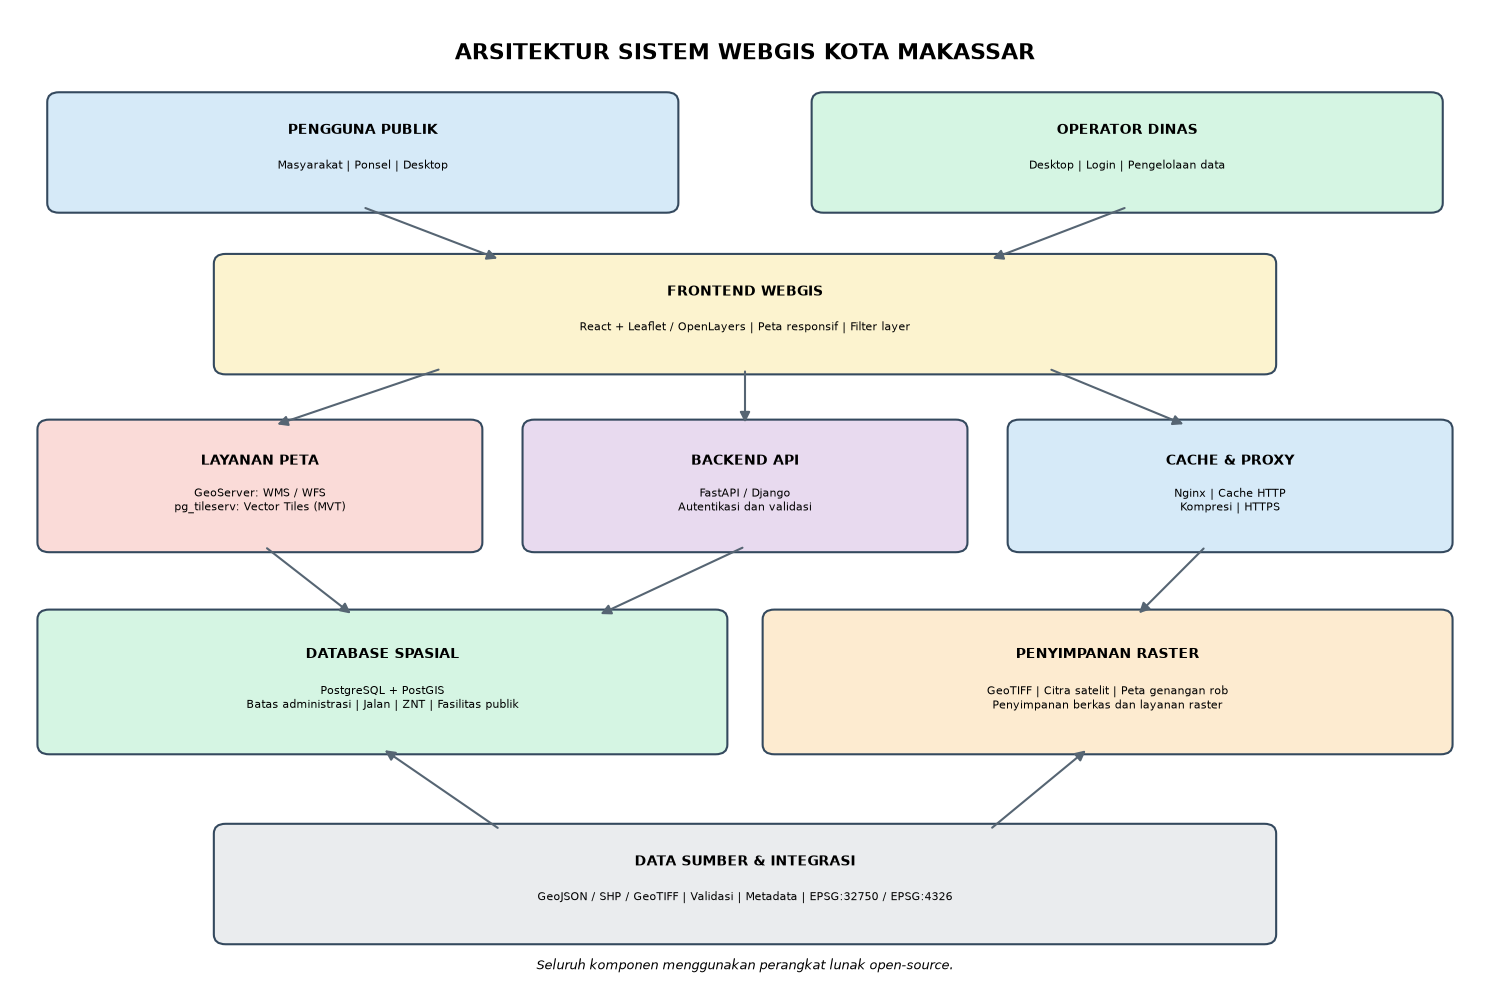

Diagram berhasil dibuat: arsitektur_webgis_makassar.png


In [7]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# =========================================================
# 1. MENYIAPKAN KANVAS DIAGRAM
# =========================================================

fig, ax = plt.subplots(figsize=(15, 10))

# Mengatur rentang kanvas dan menyembunyikan sumbu
ax.set_xlim(0, 15)
ax.set_ylim(0, 12)
ax.axis("off")

# =========================================================
# 2. MEMBUAT FUNGSI UNTUK KOTAK ARSITEKTUR
# =========================================================

def buat_kotak(x, y, lebar, tinggi, judul, isi, warna):
    # Membuat kotak dengan sudut membulat
    kotak = FancyBboxPatch(
        (x, y),
        lebar,
        tinggi,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="#34495E",
        facecolor=warna
    )
    ax.add_patch(kotak)

    # Menampilkan judul dan isi kotak
    ax.text(
        x + lebar / 2,
        y + tinggi * 0.72,
        judul,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        x + lebar / 2,
        y + tinggi * 0.37,
        isi,
        ha="center",
        va="center",
        fontsize=8,
        wrap=True
    )

# =========================================================
# 3. LAPISAN PENGGUNA
# =========================================================

buat_kotak(
    0.5, 9.6, 6.2, 1.25,
    "PENGGUNA PUBLIK",
    "Masyarakat | Ponsel | Desktop",
    "#D6EAF8"
)

buat_kotak(
    8.3, 9.6, 6.2, 1.25,
    "OPERATOR DINAS",
    "Desktop | Login | Pengelolaan data",
    "#D5F5E3"
)

# =========================================================
# 4. LAPISAN ANTARMUKA WEBGIS
# =========================================================

buat_kotak(
    2.2, 7.6, 10.6, 1.25,
    "FRONTEND WEBGIS",
    "React + Leaflet / OpenLayers | Peta responsif | Filter layer",
    "#FCF3CF"
)

# =========================================================
# 5. LAPISAN LAYANAN PETA DAN API
# =========================================================

buat_kotak(
    0.4, 5.4, 4.3, 1.4,
    "LAYANAN PETA",
    "GeoServer: WMS / WFS\npg_tileserv: Vector Tiles (MVT)",
    "#FADBD8"
)

buat_kotak(
    5.35, 5.4, 4.3, 1.4,
    "BACKEND API",
    "FastAPI / Django\nAutentikasi dan validasi",
    "#E8DAEF"
)

buat_kotak(
    10.3, 5.4, 4.3, 1.4,
    "CACHE & PROXY",
    "Nginx | Cache HTTP\nKompresi | HTTPS",
    "#D6EAF8"
)

# =========================================================
# 6. LAPISAN PENYIMPANAN DATA
# =========================================================

buat_kotak(
    0.4, 2.9, 6.8, 1.55,
    "DATABASE SPASIAL",
    "PostgreSQL + PostGIS\nBatas administrasi | Jalan | ZNT | Fasilitas publik",
    "#D5F5E3"
)

buat_kotak(
    7.8, 2.9, 6.8, 1.55,
    "PENYIMPANAN RASTER",
    "GeoTIFF | Citra satelit | Peta genangan rob\nPenyimpanan berkas dan layanan raster",
    "#FDEBD0"
)

# =========================================================
# 7. LAPISAN DATA SUMBER
# =========================================================

buat_kotak(
    2.2, 0.55, 10.6, 1.25,
    "DATA SUMBER & INTEGRASI",
    "GeoJSON / SHP / GeoTIFF | Validasi | Metadata | EPSG:32750 / EPSG:4326",
    "#EAECEE"
)

# =========================================================
# 8. MEMBUAT PANAH ALIRAN DATA DAN PERMINTAAN
# =========================================================

def buat_panah(x1, y1, x2, y2):
    # Panah menunjukkan arah komunikasi antar lapisan
    panah = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.5,
        color="#566573"
    )
    ax.add_patch(panah)

# Pengguna menuju antarmuka
buat_panah(3.6, 9.55, 5.0, 8.9)
buat_panah(11.4, 9.55, 10.0, 8.9)

# Antarmuka menuju layanan
buat_panah(4.4, 7.55, 2.7, 6.85)
buat_panah(7.5, 7.55, 7.5, 6.85)
buat_panah(10.6, 7.55, 12.0, 6.85)

# Layanan menuju penyimpanan
buat_panah(2.6, 5.35, 3.5, 4.5)
buat_panah(7.5, 5.35, 6.0, 4.5)
buat_panah(12.2, 5.35, 11.5, 4.5)

# Data sumber menuju penyimpanan
buat_panah(5.0, 1.85, 3.8, 2.85)
buat_panah(10.0, 1.85, 11.0, 2.85)

# =========================================================
# 9. JUDUL DAN CATATAN DIAGRAM
# =========================================================

ax.text(
    7.5, 11.45,
    "ARSITEKTUR SISTEM WEBGIS KOTA MAKASSAR",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    7.5, 0.12,
    "Seluruh komponen menggunakan perangkat lunak open-source.",
    ha="center",
    fontsize=9,
    style="italic"
)

# Mengatur tata letak agar semua elemen terlihat
plt.tight_layout()

# Menyimpan diagram dalam resolusi tinggi
plt.savefig(
    "arsitektur_webgis_makassar.png",
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan diagram
plt.show()

print("Diagram berhasil dibuat: arsitektur_webgis_makassar.png")
